# Unsupervised results

Read the new experiment database; `RUN_REPORT` refreshes queryable `unsupervised_report_*` snapshots there. Search chooses minimum record-disjoint CV NLL **inside each study/panel only**. Full refits and ablations inherit `source_validation_nll`; it is not an ablation likelihood. NLL selects density fit, not match accuracy or calibrated match probabilities. Gold evaluates every F1 and selects only the separately flagged oracle cuts. Nonconverged fits remain visible as finite-budget results.

The refined sweep adds `c_bay ∈ {0, .0001}` because CV NLL selected the original grid's lower boundary. It reuses the six original configurations and selects among all ten within each panel, without gold. Original B-paper/B-code baselines come from `REFERENCE_EXPERIMENT`.

Distribution fitting and decision rules remain separate. Stored in-model transitivity experiments are excluded from these reports.

Primary comparison: the five prior KaLM operating points at PC ≥ .90, with explicit missing-result coverage below. The 19 ladder cells are sensitivity checks; they do not choose a new blocker.

`hard_em` is a diagnostic ablation: **hard latent assignments during fitting; no in-fit matching constraint**. Its results are reported separately from selected soft-EM claims. Component mean differences and negative-block counts are diagnostics, not additional selection criteria.

Coverage is `partial` while work is pending, `finished_with_failures` when all required attempts are terminal but a refit/baseline failed or a finished search has no valid configuration, and `complete` when all required results succeeded. Failed fits remain reported; no substitute configuration is selected.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import sqlite3
import zlib
import numpy as np
import pandas as pd
from IPython.display import display
from config import OUTPUT_DIR, LADDER

DATABASE = Path(OUTPUT_DIR) / "optuna_unsupervised.db"
EXPERIMENT = "unsupervised-refined-v1"
REFERENCE_EXPERIMENT = "unsupervised-baselines-v2"  # fixed original baselines, all 22 cells
EXPECTED_PANELS = 27
PRIMARY_CELLS = (("fodors_zagats", "right", 1), ("dblp_acm", "right", 1),
                 ("abt_buy", "left", 2), ("amazon_googleproducts", "left", 4),
                 ("dblp_scholar", "left", 6))
SENSITIVITY_CELLS = {(dataset, side, k) for dataset, rows in LADDER.items() for side, k in rows}
REPORT_CELLS = sorted(SENSITIVITY_CELLS | set(PRIMARY_CELLS))
EXPECTED_SEARCH_STUDIES = len(REPORT_CELLS) * EXPECTED_PANELS  # 594
EXPECTED_PRIMARY_SEARCH_STUDIES = len(PRIMARY_CELLS) * EXPECTED_PANELS  # 135
EXPECTED_SENSITIVITY_SEARCH_STUDIES = len(SENSITIVITY_CELLS) * EXPECTED_PANELS  # 513
pd.set_option("display.max_columns", 30)


In [2]:
def read_sources(database=DATABASE, experiment=EXPERIMENT, reference_experiment=REFERENCE_EXPERIMENT):
    """One read snapshot; optional results/timing tables may still be pending."""
    if not Path(database).exists():
        return {name: pd.DataFrame() for name in
                ("studies", "trials", "decisions", "timing_repeats")}
    with sqlite3.connect(Path(database).resolve().as_uri() + "?mode=ro", uri=True, timeout=120) as con:
        con.execute("BEGIN")
        tables = {row[0] for row in con.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        required = {"studies", "study_user_attributes", "trials", "trial_user_attributes", "trial_values", "trial_params"}
        if not required <= tables:
            return {name: pd.DataFrame() for name in
                    ("studies", "trials", "decisions", "timing_repeats")}
        studies = pd.read_sql_query("""
            WITH attrs AS (
                SELECT study_id, json_group_object(key, json(value_json)) AS a
                FROM study_user_attributes GROUP BY study_id
            )
            SELECT s.study_id, s.study_name,
                json_extract(a, '$.experiment') AS experiment,
                json_extract(a, '$.dataset') AS dataset,
                json_extract(a, '$.side') AS side,
                json_extract(a, '$.k') AS k,
                json_extract(a, '$.phase') AS phase,
                coalesce(json_extract(a, '$.role'), json_extract(a, '$.phase')) AS role,
                json_extract(a, '$.panel_name') AS panel_name,
                json_extract(a, '$.selection') AS selection,
                json_extract(a, '$.objective') AS objective,
                json_extract(a, '$.spec.panel.fusion') AS fusion,
                json_extract(a, '$.spec.panel.models') AS models_json,
                json_extract(a, '$.spec.panel.metrics') AS metrics_json,
                json_extract(a, '$.spec.panel.attributes') AS attributes_json,
                json_extract(a, '$.spec.input_hash') AS input_hash,
                json_extract(a, '$.spec.code_hash') AS code_hash,
                json_extract(a, '$.protocol_hash') AS protocol_hash,
                json_extract(a, '$.refit_hash') AS refit_hash,
                json_extract(a, '$.policy.config_override') AS config_override_json,
                json_extract(a, '$.spec.score_state') AS score_state,
                json_extract(a, '$.refinement_source_study') AS refinement_source_study,
                json_extract(a, '$.refinement_source_experiment') AS refinement_source_experiment,
                json_extract(a, '$.refinement_source_protocol_hash') AS refinement_source_protocol_hash,
                json_extract(a, '$.copied_trials') AS copied_trials,
                CASE WHEN json_extract(a, '$.phase') = 'full' THEN 1
                     ELSE (SELECT count(*) FROM json_each(json_extract(a, '$.spec.configs')))
                END AS expected_trials
            FROM studies s JOIN attrs USING (study_id)
            WHERE (json_extract(a, '$.experiment') = ?
               OR (json_extract(a, '$.experiment') = ? AND json_extract(a, '$.phase') = 'baseline'))
              AND coalesce(json_extract(a, '$.role'), '') <> 'excluded'
              AND coalesce(json_extract(a, '$.selection'), '') <> 'in_model_transitivity'
              AND coalesce(json_extract(a, '$.excluded'), 0) = 0
            ORDER BY dataset, side, k, panel_name, phase, selection
        """, con, params=(experiment, reference_experiment))
        trials = pd.read_sql_query("""
            WITH attrs AS (
                SELECT trial_id, json_group_object(key, json(value_json)) AS a
                FROM trial_user_attributes
                WHERE key IN ('config_name', 'config_hash', 'folds', 'n_errors', 'n_validation',
                    'validation_nll', 'source_study', 'source_trial', 'source_experiment', 'source_protocol_hash',
                    'copied', 'baseline', 'error', 'seconds',
                    'fit_seconds', 'score_seconds', 'preprocessing_seconds', 'loading_seconds',
                    'load_timings', 'n_iter', 'converged', 'init_fraction', 'pi', 'final_parameter_pi',
                    'kappa_capped', 'component_mean_difference', 'n_features', 'n_no_features', 'n_informative', 'candset_size',
                    'tp_blocking', 'n_gold', 'brier', 'label_log_loss', 'scores_path', 'feature_generation')
                GROUP BY trial_id
            ), parameters AS (
                SELECT trial_id, json_group_object(param_name,
                    CASE WHEN json_extract(distribution_json, '$.name') = 'CategoricalDistribution'
                         THEN json_extract(distribution_json,
                              '$.attributes.choices[' || CAST(param_value AS INTEGER) || ']')
                         ELSE param_value END) AS params_json
                FROM trial_params GROUP BY trial_id
            )
            SELECT t.study_id, t.trial_id, t.number AS trial_number, t.state,
                t.datetime_start, t.datetime_complete, v.value AS objective_value,
                p.params_json, json_extract(a, '$.config_name') AS config_name,
                json_extract(a, '$.config_hash') AS config_hash,
                json_extract(a, '$.source_study') AS source_study,
                json_extract(a, '$.source_trial') AS source_trial,
                json_extract(a, '$.source_experiment') AS source_experiment,
                json_extract(a, '$.source_protocol_hash') AS source_protocol_hash,
                coalesce(json_extract(a, '$.copied'), 0) AS copied,
                json_extract(a, '$.validation_nll') AS recorded_validation_nll,
                json_extract(a, '$.baseline') AS baseline,
                json_extract(a, '$.folds') AS folds_json,
                json_extract(a, '$.n_errors') AS n_errors,
                json_extract(a, '$.n_validation') AS n_validation,
                json_extract(a, '$.error') AS error,
                json_extract(a, '$.seconds') AS wall_seconds,
                json_extract(a, '$.fit_seconds') AS fit_seconds,
                json_extract(a, '$.score_seconds') AS score_seconds,
                json_extract(a, '$.preprocessing_seconds') AS preprocessing_seconds,
                coalesce(json_extract(a, '$.loading_seconds'),
                         json_extract(a, '$.load_timings.loading_seconds')) AS loading_seconds,
                json_extract(a, '$.load_timings.similarity_seconds') AS cached_similarity_seconds,
                json_extract(a, '$.load_timings.preprocessing_seconds') AS input_preprocessing_seconds,
                json_extract(a, '$.n_iter') AS n_iter,
                json_extract(a, '$.converged') AS converged,
                json_extract(a, '$.init_fraction') AS init_fraction,
                coalesce(json_extract(a, '$.pi'), json_extract(a, '$.final_parameter_pi')) AS pi,
                json_extract(a, '$.kappa_capped') AS kappa_capped,
                json_extract(a, '$.component_mean_difference') AS component_mean_difference_json,
                json_extract(a, '$.n_features') AS n_features,
                json_extract(a, '$.n_no_features') AS n_no_features,
                json_extract(a, '$.candset_size') AS candset_size,
                json_extract(a, '$.tp_blocking') AS tp_blocking,
                json_extract(a, '$.n_gold') AS n_gold,
                json_extract(a, '$.brier') AS brier,
                json_extract(a, '$.label_log_loss') AS label_log_loss,
                json_extract(a, '$.scores_path') AS scores_path,
                json_extract(a, '$.feature_generation') AS feature_generation
            FROM trials t JOIN study_user_attributes e ON e.study_id=t.study_id
                AND e.key='experiment' AND (json_extract(e.value_json, '$')=?
                    OR (json_extract(e.value_json, '$')=? AND EXISTS (
                        SELECT 1 FROM study_user_attributes ph WHERE ph.study_id=t.study_id
                        AND ph.key='phase' AND json_extract(ph.value_json, '$')='baseline')))
            LEFT JOIN attrs USING (trial_id)
            LEFT JOIN parameters p USING (trial_id)
            LEFT JOIN trial_values v ON v.trial_id=t.trial_id AND v.objective=0
            ORDER BY t.study_id, t.number
        """, con, params=(experiment, reference_experiment)).merge(studies, on="study_id", how="inner", validate="many_to_one")
        trials["source_experiment"] = trials.source_experiment.fillna(trials.experiment)
        trials["cv_validation_nll"] = trials.objective_value.where(trials.phase.eq("search"))
        trials["source_validation_nll"] = trials.recorded_validation_nll.where(trials.phase.eq("full"))
        trials["n_unconverged_folds"] = trials.folds_json.map(
            lambda value: sum(fold.get("converged") is False for fold in json.loads(value or "[]")))
        trials = trials.drop(columns=["objective_value", "recorded_validation_nll"])
        for parameter in ("c_bay", "init_statistic", "missing", "hard", "transitivity"):
            trials[parameter] = trials.params_json.map(
                lambda value: json.loads(value or "{}").get(parameter))
        trials["fit_policy_label"] = np.where(trials.hard.eq(1),
            "hard latent assignments during fitting; no in-fit matching constraint",
            "soft latent assignments during fitting; no in-fit matching constraint")
        trials["claim_scope"] = np.where(trials.role.eq("ablation"), "diagnostic_ablation",
            np.where(trials.role.eq("selected") & trials.hard.eq(0), "selected_soft_em",
                     np.where(trials.phase.eq("baseline"), "baseline_comparator", "configuration_search")))
        mean_differences = trials.component_mean_difference_json.map(
            lambda value: json.loads(value) if isinstance(value, str) else None)
        trials["record_component_mean_difference"] = mean_differences.map(
            lambda value: value.get("record") if value is not None else None)
        trials["negative_mean_block_count"] = mean_differences.map(
            lambda value: sum(difference < 0 for difference in value.values()) if value is not None else None)
        decisions = pd.DataFrame()
        if "unsupervised_decisions" in tables:
            decisions = pd.read_sql_query("""
                SELECT d.* FROM unsupervised_decisions d
                JOIN studies s USING (study_name)
                JOIN study_user_attributes e ON e.study_id=s.study_id
                    AND e.key='experiment' AND (json_extract(e.value_json, '$')=?
                        OR (json_extract(e.value_json, '$')=? AND EXISTS (
                            SELECT 1 FROM study_user_attributes ph WHERE ph.study_id=s.study_id
                            AND ph.key='phase' AND json_extract(ph.value_json, '$')='baseline')))
            """, con, params=(experiment, reference_experiment))
            metadata = trials.drop(columns=["folds_json", "error", "n_gold"])
            decisions = decisions.merge(metadata, on=["study_name", "trial_number"],
                                          how="inner", validate="many_to_one")
            decisions = decisions.loc[decisions.state.eq("COMPLETE")].copy()
            decisions["metrics_use_gold"] = 1
            decisions["blocking_recall"] = decisions.tp_blocking / decisions.n_gold.replace(0, np.nan)
            decisions["candidate_prevalence"] = decisions.tp_blocking / decisions.candset_size.replace(0, np.nan)
        timing = pd.DataFrame()
        if "unsupervised_timings" in tables:
            timing = pd.read_sql_query("""
                SELECT tm.* FROM unsupervised_timings tm
                JOIN studies s USING (study_name)
                JOIN study_user_attributes e ON e.study_id=s.study_id
                    AND e.key='experiment' AND (json_extract(e.value_json, '$')=?
                        OR (json_extract(e.value_json, '$')=? AND EXISTS (
                            SELECT 1 FROM study_user_attributes ph WHERE ph.study_id=s.study_id
                            AND ph.key='phase' AND json_extract(ph.value_json, '$')='baseline')))
            """, con, params=(experiment, reference_experiment))
            timing = timing.merge(studies, on="study_name", how="inner", validate="many_to_one")
            for key in ("source_study", "source_trial", "rule", "uses_gold", "similarity_scope",
                        "conservative_baseline_cost", "shared_costs_across_rules", "cache_state"):
                timing[key] = timing.metadata_json.map(lambda value: json.loads(value).get(key))
        cosine_timing = pd.DataFrame()
        if "unsupervised_cosine_timings" in tables:
            cosine_timing = pd.read_sql_query("SELECT * FROM unsupervised_cosine_timings", con)
            cells = pd.DataFrame(REPORT_CELLS, columns=["dataset", "side", "k"])
            cosine_timing = cosine_timing.merge(cells, on=["dataset", "side", "k"], validate="many_to_one")
            for key in ("rule", "uses_gold", "cost_scope", "cache_state", "shared_costs_across_rules", "protocol_hash"):
                cosine_timing[key] = cosine_timing.metadata_json.map(lambda value: json.loads(value).get(key))
            cosine_timing["experiment_scope"] = "shared candidate-cell timing; source has no experiment field"
        baseline_timing = pd.DataFrame()
        if "unsupervised_baseline_timings" in tables:
            baseline_timing = pd.read_sql_query("SELECT * FROM unsupervised_baseline_timings", con).rename(
                columns={"queried_side": "side", "top_k": "k"})
            for key in ("rule", "uses_gold", "cache_state", "shared_costs_across_rules",
                        "shared_similarity_across_baselines", "protocol_hash", "max_absolute_difference"):
                baseline_timing[key] = baseline_timing.metadata_json.map(lambda value: json.loads(value).get(key))
            baseline_timing["experiment_scope"] = "shared candidate-cell timing; source has no experiment field"
        return dict(studies=studies, trials=trials, decisions=decisions,
                    timing_repeats=timing, cosine_timing_repeats=cosine_timing,
                    baseline_timing_repeats=baseline_timing)


In [3]:
def terminal_outcomes(frame, keys):
    """One outcome per configuration/refit; a successful retry supersedes failure."""
    if frame.empty:
        return pd.DataFrame(columns=keys + ["complete", "terminal", "failed"])
    result = frame.groupby(keys, dropna=False).state.agg(list).reset_index()
    result["complete"] = result.state.map(lambda states: "COMPLETE" in states)
    result["terminal"] = result.complete | result.state.map(
        lambda states: all(state in ("COMPLETE", "FAIL", "PRUNED") for state in states))
    result["failed"] = result.terminal & ~result.complete
    return result.drop(columns="state")


def completion_status(expected_searches, finished_searches, no_valid_searches,
                      completed_refits, terminal_refits, completed_baselines,
                      terminal_baselines, expected_baselines):
    finished = (finished_searches == expected_searches
                and terminal_refits + no_valid_searches == expected_searches
                and terminal_baselines == expected_baselines)
    if not finished:
        return "partial"
    return ("complete" if completed_refits == expected_searches
            and completed_baselines == expected_baselines else "finished_with_failures")


def make_reports(sources, experiment=EXPERIMENT):
    studies, trials, decisions, timing = (sources[key].copy() for key in
                                          ("studies", "trials", "decisions", "timing_repeats"))
    cosine_timing = sources.get("cosine_timing_repeats", pd.DataFrame()).copy()
    baseline_timing = sources.get("baseline_timing_repeats", pd.DataFrame()).copy()
    reports = {}
    if studies.empty:
        reports["coverage"] = pd.DataFrame([dict(experiment=experiment,
            expected_search_studies=EXPECTED_SEARCH_STUDIES,
            expected_primary_search_studies=EXPECTED_PRIMARY_SEARCH_STUDIES,
            expected_sensitivity_search_studies=EXPECTED_SENSITIVITY_SEARCH_STUDIES, search_studies=0,
            studies_with_selection=0, search_studies_without_valid_configuration=0,
            selected_refits=0, selected_refits_terminal=0, selected_refits_failed=0,
            baseline_trials=0, baseline_trials_terminal=0, baseline_trials_failed=0,
            expected_baseline_trials=2 * len(REPORT_CELLS),
            timed_studies=0, status="partial")])
        for name in ("studies", "trials", "selection", "failures", "run_costs", "decisions", "practical",
                     "oracles", "baselines", "dataset_summary", "development_summary", "timing_repeats", "timings", "cosine_timing_repeats", "cosine_timings", "baseline_timing_repeats", "baseline_timings", "calibration"):
            reports[name] = pd.DataFrame(columns=["experiment", "dataset", "study_name"])
        for frame in reports.values():
            frame["report_created_utc"] = datetime.now(timezone.utc).isoformat()
        return reports
    counts = trials.groupby(["study_name", "state"]).size().unstack(fill_value=0)
    for state in ("COMPLETE", "FAIL", "RUNNING", "WAITING"):
        studies["n_" + state.lower()] = studies.study_name.map(
            counts[state] if state in counts else pd.Series(dtype=int)).fillna(0).astype(int)
    studies["n_trials"] = studies.study_name.map(trials.groupby("study_name").size()).fillna(0).astype(int)
    configurations = terminal_outcomes(trials, ["study_name", "config_hash"])
    terminal_counts = configurations.loc[configurations.terminal.astype(bool)].groupby("study_name").size()
    studies["n_terminal_configurations"] = studies.study_name.map(terminal_counts).fillna(0).astype(int)
    studies["finished"] = studies.n_terminal_configurations >= studies.expected_trials
    eligible = trials.loc[trials.phase.eq("search") & trials.state.eq("COMPLETE")
                          & np.isfinite(pd.to_numeric(trials.cv_validation_nll, errors="coerce"))]
    # Sorting is scoped to study_id. No NLL ranking across panels or cells.
    choices = eligible.sort_values(["study_id", "cv_validation_nll", "trial_number"]).drop_duplicates("study_id")
    choice_columns = ["study_id", "trial_id", "trial_number", "config_name", "params_json",
                      "cv_validation_nll", "n_validation", "n_unconverged_folds", "c_bay", "init_statistic", "missing",
                      "copied", "source_experiment", "source_study", "source_trial"]
    selection = studies.loc[studies.phase.eq("search")].merge(
        choices[choice_columns], on="study_id", how="left", validate="one_to_one")
    selection["choice_status"] = np.where(selection.trial_id.notna(),
        np.where(selection.finished, "selected", "provisional: search running"),
        np.where(selection.finished, "no eligible configuration", "pending"))
    trials["selected_within_study"] = trials.trial_id.isin(choices.trial_id).astype(int)
    failures = []
    for row in trials.itertuples(index=False):
        metadata = {key: getattr(row, key) for key in ("experiment", "dataset", "side", "k",
            "panel_name", "phase", "role", "selection", "study_name", "trial_number", "config_name", "state")}
        for fold in json.loads(row.folds_json or "[]"):
            if "error" in fold:
                failures.append(dict(metadata, fold=fold.get("fold"), error=fold["error"],
                    n_train=fold.get("n_train"), n_validation=fold.get("n_validation")))
        if pd.notna(row.error):
            failures.append(dict(metadata, fold=None, error=row.error, n_train=None, n_validation=None))
    failure_columns = ["experiment", "dataset", "side", "k", "panel_name", "phase", "role", "selection",
                       "study_name", "trial_number", "config_name", "state", "fold", "error", "n_train", "n_validation"]
    reports.update(studies=studies, trials=trials.drop(columns=["folds_json"]), selection=selection,
                   failures=pd.DataFrame(failures, columns=failure_columns))
    refit_outcomes = terminal_outcomes(trials.loc[trials.phase.eq("full") & trials.role.eq("selected")],
                                       ["study_name"])
    baseline_outcomes = terminal_outcomes(trials.loc[trials.phase.eq("baseline")],
                                          ["study_name", "config_hash"])
    no_valid_searches = int((selection.finished & selection.trial_id.isna()).sum())
    finished_searches = int((studies.phase.eq("search") & studies.finished).sum())
    coverage_status = completion_status(EXPECTED_SEARCH_STUDIES, finished_searches, no_valid_searches,
        int(refit_outcomes.complete.sum()), int(refit_outcomes.terminal.sum()),
        int(baseline_outcomes.complete.sum()), int(baseline_outcomes.terminal.sum()), 2 * len(REPORT_CELLS))
    reports["coverage"] = pd.DataFrame([dict(experiment=experiment,
        expected_search_studies=EXPECTED_SEARCH_STUDIES,
        expected_primary_search_studies=EXPECTED_PRIMARY_SEARCH_STUDIES,
        expected_sensitivity_search_studies=EXPECTED_SENSITIVITY_SEARCH_STUDIES,
        search_studies=int(studies.phase.eq("search").sum()),
        finished_search_studies=finished_searches,
        studies_with_selection=len(choices), search_studies_without_valid_configuration=no_valid_searches,
        selected_refits=int(refit_outcomes.complete.sum()),
        selected_refits_terminal=int(refit_outcomes.terminal.sum()),
        selected_refits_failed=int(refit_outcomes.failed.sum()),
        baseline_trials=int(baseline_outcomes.complete.sum()),
        baseline_trials_terminal=int(baseline_outcomes.terminal.sum()),
        baseline_trials_failed=int(baseline_outcomes.failed.sum()),
        expected_baseline_trials=2 * len(REPORT_CELLS),
        timed_studies=timing.study_name.nunique() if not timing.empty else 0,
        direct_cosine_cells=len(cosine_timing[["dataset", "side", "k"]].drop_duplicates()) if not cosine_timing.empty else 0,
        fresh_baseline_cells=len(baseline_timing[["dataset", "side", "k"]].drop_duplicates()) if not baseline_timing.empty else 0,
        status=coverage_status)])
    # Fold preprocessing is shared across configurations; refit wall time includes reporting/writes.
    cost_rows = []
    cost_columns = ["experiment", "dataset", "side", "k", "panel_name", "phase", "role", "selection",
                    "study_name", "trial_number", "config_name", "state", "copied", "source_experiment", "source_study", "source_trial",
                    "fold", "timing_kind",
                    "loading_seconds", "similarity_seconds", "preprocessing_seconds", "fit_seconds",
                    "score_seconds", "wall_seconds"]
    for row in trials.itertuples(index=False):
        base = {key: getattr(row, key) for key in cost_columns[:16]}
        if row.phase == "search":
            for fold in json.loads(row.folds_json or "[]"):
                cost_rows.append(dict(base, fold=fold.get("fold"), timing_kind="search_fold",
                    **{key: fold.get(key) for key in ("preprocessing_seconds", "fit_seconds", "score_seconds")}))
        else:
            cost_rows.append(dict(base, fold=None, timing_kind="cached_refit_or_baseline",
                loading_seconds=row.loading_seconds, similarity_seconds=row.cached_similarity_seconds,
                preprocessing_seconds=row.preprocessing_seconds, fit_seconds=row.fit_seconds,
                score_seconds=row.score_seconds, wall_seconds=row.wall_seconds))
    reports["run_costs"] = pd.DataFrame(cost_rows, columns=cost_columns)
    reports["run_costs"]["preprocessing_shared_across_configurations"] = reports["run_costs"].phase.eq("search").astype(int)
    calibration_columns = ["experiment", "dataset", "side", "k", "panel_name", "role", "selection",
        "study_name", "trial_number", "source_study", "source_trial", "source_validation_nll",
        "converged", "n_iter", "pi", "init_fraction", "kappa_capped", "n_no_features",
        "candset_size", "brier", "label_log_loss", "fit_policy_label", "claim_scope",
        "component_mean_difference_json", "record_component_mean_difference", "negative_mean_block_count"]
    reports["calibration"] = trials.loc[trials.phase.eq("full") & trials.state.eq("COMPLETE"),
                                        calibration_columns].copy()
    reports["calibration"]["pi_times_k"] = reports["calibration"].pi * reports["calibration"].k
    reports["calibration"]["metrics_use_gold"] = 1
    reports["calibration"]["population"] = "candidate pairs"
    if not decisions.empty:
        fixed = decisions.loc[decisions.uses_gold.eq(0)].copy()
        cut = pd.to_numeric(fixed.threshold_json, errors="coerce")
        primary = ((fixed.score_name.eq("llr") & cut.eq(0))
                   | (fixed.score_name.isin(["posterior", "legacy_posterior"]) & cut.eq(.5)))
        practical = fixed.loc[(fixed.rule.eq("fixed") & primary)
                             | (fixed.decoder.eq("greedy") & fixed.rule.eq("pure_transitivity"))].copy()
        practical["decision_label"] = np.where(practical.rule.eq("pure_transitivity"),
            practical.score_name + ":greedy:no-cut",
            practical.score_name + ":" + practical.decoder + ":" + practical.threshold_json)
        oracle = decisions.loc[decisions.uses_gold.eq(1)].copy()
        join_keys = ["study_name", "trial_number", "decoder"]
        reference_specs = [("llr0", "llr", 0.), ("posterior05", "posterior", .5),
                           ("legacy_posterior05", "legacy_posterior", .5)]
        for label, score, threshold in reference_specs:
            reference = fixed.loc[fixed.rule.eq("fixed") & fixed.score_name.eq(score) & cut.eq(threshold),
                                  join_keys + ["f1"]].drop_duplicates(join_keys)
            oracle = oracle.merge(reference.rename(columns={"f1": label + "_f1"}),
                                  on=join_keys, how="left", validate="many_to_one")
            oracle["gain_vs_" + label] = oracle.f1 - oracle[label + "_f1"]
        for score in ("llr", "posterior"):
            no_cut_reference = fixed.loc[fixed.rule.eq("pure_transitivity") & fixed.score_name.eq(score),
                ["study_name", "trial_number", "f1"]].drop_duplicates(["study_name", "trial_number"])
            oracle = oracle.merge(no_cut_reference.rename(columns={"f1": score + "_nocut_f1"}),
                on=["study_name", "trial_number"], how="left", validate="many_to_one")
            oracle["gain_vs_" + score + "_nocut"] = oracle.f1 - oracle[score + "_nocut_f1"]
        same_keys = ["study_name", "trial_number", "score_name"]
        no_cut = fixed.loc[fixed.rule.eq("pure_transitivity"), same_keys + ["f1"]].drop_duplicates(same_keys)
        oracle = oracle.merge(no_cut.rename(columns={"f1": "same_score_nocut_f1"}),
                              on=same_keys, how="left", validate="many_to_one")
        oracle["gain_vs_same_score_nocut"] = oracle.f1 - oracle.same_score_nocut_f1
        oracle["comparison_note"] = "gold-selected oracle diagnostic; no fit or panel selection"
        reports.update(decisions=decisions, practical=practical, oracles=oracle,
                       baselines=decisions.loc[decisions.phase.eq("baseline")].copy())
        # Keep each method, panel and ablation separate. Equal dataset weights,
        # after averaging the declared cells within each dataset.
        practical["method"] = np.where(practical.phase.eq("baseline"), practical.baseline,
                                        practical.selection.fillna("cv_nll"))
        keys = ["panel_name", "role", "method", "decision_label"]
        sensitivity = practical.merge(pd.DataFrame(sorted(SENSITIVITY_CELLS),
            columns=["dataset", "side", "k"]), on=["dataset", "side", "k"], how="inner", validate="many_to_one")
        dataset = sensitivity.groupby(keys + ["dataset"], dropna=False).agg(
            mean_f1=("f1", "mean"), mean_precision=("precision", "mean"),
            mean_recall=("recall", "mean"), cells=("study_name", "nunique")).reset_index()
        dataset["expected_cells"] = dataset.dataset.map({name: len(rows) for name, rows in LADDER.items()})
        dataset["complete_dataset"] = dataset.cells.eq(dataset.expected_cells)
        development = dataset.groupby(keys, dropna=False).agg(
            dataset_equal_f1=("mean_f1", "mean"), dataset_equal_precision=("mean_precision", "mean"),
            dataset_equal_recall=("mean_recall", "mean"), datasets=("dataset", "nunique"),
            cells=("cells", "sum"), complete_datasets=("complete_dataset", "sum")).reset_index()
        development["expected_datasets"] = len(LADDER)
        development["complete_coverage"] = development.complete_datasets.eq(len(LADDER))
        development["interpretation"] = "19-cell sensitivity ranking using gold; not an unsupervised method selection"
        reports.update(dataset_summary=dataset, development_summary=development)
    reports["timing_repeats"] = timing
    if not timing.empty:
        timing_keys = ["experiment", "dataset", "side", "k", "panel_name", "role", "selection",
                       "study_name", "score_name", "decoder", "threshold_json", "rule", "similarity_scope",
                       "conservative_baseline_cost", "shared_costs_across_rules", "cache_state"]
        stages = ["loading_seconds", "similarity_seconds", "preprocessing_seconds", "fit_seconds",
                  "score_seconds", "decode_seconds", "matching_seconds", "total_seconds"]
        aggregates = {"repeats": ("repeat", "nunique")}
        aggregates.update({stage + "_median": (stage, "median") for stage in stages})
        aggregates.update(matching_seconds_min=("matching_seconds", "min"),
                          matching_seconds_max=("matching_seconds", "max"))
        reports["timings"] = timing.groupby(timing_keys, dropna=False).agg(**aggregates).reset_index()
    reports["cosine_timing_repeats"] = cosine_timing
    if not cosine_timing.empty:
        keys = ["dataset", "side", "k", "score_name", "models_json", "decoder", "threshold_json",
                "rule", "cost_scope", "cache_state", "shared_costs_across_rules", "experiment_scope"]
        stages = ["loading_seconds", "similarity_seconds", "preprocessing_seconds", "aggregation_seconds",
                  "decode_seconds", "matching_seconds", "total_seconds"]
        aggregates = {"repeats": ("repeat", "nunique")}
        aggregates.update({stage + "_median": (stage, "median") for stage in stages})
        aggregates.update(matching_seconds_min=("matching_seconds", "min"),
                          matching_seconds_max=("matching_seconds", "max"))
        reports["cosine_timings"] = cosine_timing.groupby(keys, dropna=False).agg(**aggregates).reset_index()
    reports["baseline_timing_repeats"] = baseline_timing
    if not baseline_timing.empty:
        keys = ["dataset", "side", "k", "baseline", "score_name", "decoder", "threshold_json", "rule",
                "cache_state", "shared_costs_across_rules", "shared_similarity_across_baselines", "experiment_scope"]
        stages = ["loading_seconds", "similarity_seconds", "preprocessing_seconds", "fit_seconds",
                  "decode_seconds", "matching_seconds", "total_seconds"]
        aggregates = {"repeats": ("repeat", "nunique")}
        aggregates.update({stage + "_median": (stage, "median") for stage in stages})
        aggregates.update(matching_seconds_min=("matching_seconds", "min"),
                          matching_seconds_max=("matching_seconds", "max"))
        reports["baseline_timings"] = baseline_timing.groupby(keys, dropna=False).agg(**aggregates).reset_index()
    # Even pending sections have a queryable table after RUN_REPORT.
    for name in ("decisions", "practical", "oracles", "baselines", "dataset_summary",
                 "development_summary", "timing_repeats", "timings", "cosine_timing_repeats", "cosine_timings", "baseline_timing_repeats", "baseline_timings", "calibration"):
        if name not in reports or not len(reports[name].columns):
            reports[name] = pd.DataFrame(columns=["experiment", "dataset", "study_name"])
    stamp = datetime.now(timezone.utc).isoformat()
    for frame in reports.values():
        if "experiment" not in frame:
            frame.insert(0, "experiment", experiment)
        frame["report_created_utc"] = stamp
    return reports


def persist_reports(reports, database=DATABASE):
    if not Path(database).exists():
        raise FileNotFoundError("Run the experiments first; reporting does not create an experiment database")
    with sqlite3.connect(database, timeout=120) as con:
        for name, frame in reports.items():
            frame.to_sql("unsupervised_report_" + name, con, if_exists="replace", index=False)
    return pd.DataFrame([dict(table="unsupervised_report_" + name, rows=len(frame))
                         for name, frame in reports.items()])


In [4]:
RUN_REPORT = False
reports = make_reports(read_sources())
if RUN_REPORT:
    display(persist_reports(reports))
display(reports["coverage"])
if "selection" in reports and not reports["selection"].empty:
    display(reports["selection"][["dataset", "side", "k", "panel_name", "choice_status",
        "trial_number", "config_name", "cv_validation_nll", "n_complete", "n_fail", "n_unconverged_folds", "copied"]])
    display(reports["failures"])


,table,rows
0,unsupervised_report_studies,1254
1,unsupervised_report_trials,6622
2,unsupervised_report_selection,594
3,unsupervised_report_failures,715
4,unsupervised_report_coverage,1
5,unsupervised_report_run_costs,18502
6,unsupervised_report_calibration,637
7,unsupervised_report_decisions,67158
8,unsupervised_report_practical,7606
9,unsupervised_report_oracles,9940


,experiment,expected_search_studies,expected_primary_search_studies,expected_sensitivity_search_studies,search_studies,finished_search_studies,studies_with_selection,search_studies_without_valid_configuration,selected_refits,selected_refits_terminal,selected_refits_failed,baseline_trials,baseline_trials_terminal,baseline_trials_failed,expected_baseline_trials,timed_studies,direct_cosine_cells,fresh_baseline_cells,status,report_created_utc
0,unsupervised-refined-v1,594,135,513,594,594,594,0,593,594,1,44,44,0,44,593,22,1,finished_with_failures,2026-10-20T00:07:06.969210+00:00


,dataset,side,k,panel_name,choice_status,trial_number,config_name,cv_validation_nll,n_complete,n_fail,n_unconverged_folds,copied
0,abt_buy,left,1,all:family,selected,9,bay=0.0001:init=present_mean,-10.965556,10,0,0,0
1,abt_buy,left,1,all:mean,selected,6,bay=0.0:init=sum,-4.187550,9,1,1,0
2,abt_buy,left,1,all:separate,selected,8,bay=0.0001:init=sum,-128.113467,10,0,0,0
3,abt_buy,left,1,all:zmean,selected,6,bay=0.0:init=sum,-0.998462,8,2,0,0
4,abt_buy,left,1,classic:cos+linf,selected,6,bay=0.0:init=sum,-19.906280,10,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
589,fodors_zagats,right,4,single:minilm6,selected,6,bay=0.0:init=sum,-3.422292,8,2,0,0
590,fodors_zagats,right,4,single:mpnet,selected,6,bay=0.0:init=sum,-4.699389,8,2,0,0
591,fodors_zagats,right,4,single:nvidia_llama-embed-nemotron-8b,selected,6,bay=0.0:init=sum,-6.620779,10,0,0,0
592,fodors_zagats,right,4,single:st5_xl,selected,6,bay=0.0:init=sum,-7.864868,8,2,0,0


,experiment,dataset,side,k,panel_name,phase,role,selection,study_name,trial_number,config_name,state,fold,error,n_train,n_validation,report_created_utc
0,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm6,search,search,None,fodors_zagats_unsupervised-refined-v1_right_k4...,4,bay=0.1:init=sum,FAIL,1.0,RuntimeError('all failed to converge after 5 i...,559.0,132.0,2026-10-20T00:07:06.969210+00:00
1,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm6,search,search,None,fodors_zagats_unsupervised-refined-v1_right_k4...,5,bay=0.1:init=present_mean,FAIL,1.0,RuntimeError('all failed to converge after 5 i...,559.0,132.0,2026-10-20T00:07:06.969210+00:00
2,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm12,search,search,None,fodors_zagats_unsupervised-refined-v1_right_k4...,4,bay=0.1:init=sum,FAIL,0.0,RuntimeError('all failed to converge after 5 i...,680.0,111.0,2026-10-20T00:07:06.969210+00:00
3,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm12,search,search,None,fodors_zagats_unsupervised-refined-v1_right_k4...,4,bay=0.1:init=sum,FAIL,1.0,RuntimeError('all failed to converge after 5 i...,559.0,132.0,2026-10-20T00:07:06.969210+00:00
4,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm12,search,search,None,fodors_zagats_unsupervised-refined-v1_right_k4...,5,bay=0.1:init=present_mean,FAIL,0.0,RuntimeError('all failed to converge after 5 i...,680.0,111.0,2026-10-20T00:07:06.969210+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
710,unsupervised-refined-v1,dblp_scholar,left,6,single:microsoft_harrier-oss-v1-0.6b,search,search,None,dblp_scholar_unsupervised-refined-v1_left_k6_s...,5,bay=0.1:init=present_mean,FAIL,0.0,RuntimeError('all failed to converge after 5 i...,7190.0,1681.0,2026-10-20T00:07:06.969210+00:00
711,unsupervised-refined-v1,dblp_scholar,left,6,all:zmean,search,search,None,dblp_scholar_unsupervised-refined-v1_left_k6_a...,5,bay=0.1:init=present_mean,FAIL,0.0,RuntimeError('all failed to converge after 5 i...,7190.0,1681.0,2026-10-20T00:07:06.969210+00:00
712,unsupervised-refined-v1,dblp_scholar,left,6,classic:pair,search,search,None,dblp_scholar_unsupervised-refined-v1_left_k6_c...,4,bay=0.1:init=sum,FAIL,1.0,RuntimeError('all failed to converge after 5 i...,6767.0,1850.0,2026-10-20T00:07:06.969210+00:00
713,unsupervised-refined-v1,dblp_scholar,left,6,classic:pair,search,search,None,dblp_scholar_unsupervised-refined-v1_left_k6_c...,4,bay=0.1:init=sum,FAIL,2.0,RuntimeError('all failed to converge after 5 i...,6949.0,1679.0,2026-10-20T00:07:06.969210+00:00


## Fixed blocker and primary operating points

Candidates use **KaLM only** (`config.MODEL`). The 20 models vary the matching features on those same candidates. The previous blocker search is closed: for each model/dataset, minimize candidate count subject to **PC ≥ .90**, then prefer higher PQ; direction and k finish ties. Rank models by mean candidate-count rank, worst rank, then mean PQ. KaLM ties F2LLM-14B/8B on mean rank (1.6667) and worst rank (2), and wins the PQ tie-break (.4608 vs .4595/.4584).

The aggregate rank uses Abt–Buy, Amazon–Google and DBLP–Scholar. DBLP–ACM (20/20 first-place ties) and Fodors–Zagats (18/20) are excluded from that rank because more than half the models tie first. Mean PQ still averages all five datasets, as in the original notebook. These blocking choices used gold; matcher selection uses only within-panel CV NLL.

The **five primary points** below are the prior minimum-cost KaLM points at strict PC ≥ .90. The existing **19 ladder cells remain sensitivity checks**. Three primary points are outside that ladder (DA right/k1, AG left/k4, DS left/k6); missing matching results stay explicit. DS left/k5 has PC **.899943893772**, so rounding it to .90 does not qualify it. SQL reads `outputs/optuna.db` without changing it.


In [5]:
import sqlite3
from config import MODEL as BLOCKER_MODEL

BLOCKING_DATABASE = Path(OUTPUT_DIR) / "optuna.db"
with sqlite3.connect(BLOCKING_DATABASE.resolve().as_uri() + "?mode=ro", uri=True) as blocking_evidence_db:
    blocking_evidence_db.executescript("""
    CREATE TEMP VIEW blocking_evidence AS
    WITH params AS (
        SELECT trial_id, json_group_object(param_name,
            CASE WHEN json_extract(distribution_json, '$.name') = 'CategoricalDistribution'
                 THEN json_extract(distribution_json,
                      '$.attributes.choices[' || CAST(param_value AS INTEGER) || ']')
                 ELSE param_value END) AS p
        FROM trial_params GROUP BY trial_id
    ), attrs AS (
        SELECT trial_id, json_group_object(key, json(value_json)) AS a
        FROM trial_user_attributes GROUP BY trial_id
    ), named AS (
        SELECT study_id, CASE WHEN study_name GLOB '*_full'
            THEN substr(study_name, 1, length(study_name)-5) ELSE study_name END AS name
        FROM studies
    )
    SELECT substr(s.name, 1, length(s.name)-9) AS dataset,
        json_extract(p, '$.embedding_model') AS embedding_model,
        json_extract(p, '$.queried_side') AS side,
        CAST(json_extract(p, '$.top_k') AS INTEGER) AS k,
        json_extract(a, '$.candset_size') AS candidates,
        json_extract(a, '$.tp') AS gold_in_candidates,
        json_extract(a, '$.n_gold') AS gold_pairs,
        1.0*json_extract(a, '$.tp')/json_extract(a, '$.n_gold') AS PC,
        1.0*json_extract(a, '$.tp')/json_extract(a, '$.candset_size') AS PQ
    FROM named s JOIN trials t USING (study_id)
    JOIN params USING (trial_id) JOIN attrs USING (trial_id)
    WHERE s.name GLOB '*_blocking' AND t.state='COMPLETE';

    CREATE TEMP VIEW blocker_operating_evidence AS
    WITH eligible AS (
        SELECT *, row_number() OVER (PARTITION BY dataset, embedding_model
            ORDER BY candidates, PQ DESC, side, k) AS choice
        FROM blocking_evidence WHERE PC >= .90
    ), models AS (
        SELECT DISTINCT dataset, embedding_model FROM blocking_evidence
    )
    SELECT m.*, e.side, e.k, e.candidates, e.gold_in_candidates, e.gold_pairs, e.PC, e.PQ,
        rank() OVER (PARTITION BY m.dataset ORDER BY e.candidates IS NULL, e.candidates) AS rank
    FROM models m LEFT JOIN eligible e ON m.dataset=e.dataset
        AND m.embedding_model=e.embedding_model AND e.choice=1;

    CREATE TEMP VIEW blocker_ranking_scope AS
    SELECT dataset, count(*) AS models, sum(rank=1) AS tied_first,
        2*sum(rank=1)<=count(*) AS used_for_ranking
    FROM blocker_operating_evidence GROUP BY dataset;
    """)
    blocker_ranking = pd.read_sql_query("""
        SELECT o.embedding_model,
            round(avg(CASE WHEN s.used_for_ranking THEN o.rank END),4) AS mean_rank,
            max(CASE WHEN s.used_for_ranking THEN o.rank END) AS worst_rank,
            sum(s.used_for_ranking AND o.rank=1) AS wins,
            round(avg(o.PQ),4) AS mean_PQ,
            sum(o.candidates IS NULL) AS misses
        FROM blocker_operating_evidence o JOIN blocker_ranking_scope s USING (dataset)
        GROUP BY o.embedding_model
        ORDER BY mean_rank IS NULL, mean_rank, worst_rank, mean_PQ DESC, o.embedding_model
    """, blocking_evidence_db)
    blocker_scope = pd.read_sql_query("SELECT * FROM blocker_ranking_scope ORDER BY dataset", blocking_evidence_db)
    blocker_primary_points = pd.read_sql_query("""
        SELECT dataset, side, k, candidates, gold_in_candidates, gold_pairs, PC, PQ
        FROM blocker_operating_evidence WHERE embedding_model=? ORDER BY dataset
    """, blocking_evidence_db, params=(BLOCKER_MODEL,))
    blocker_ladder_points = pd.read_sql_query("""
        SELECT dataset, side, k, candidates, gold_in_candidates, gold_pairs, PC, PQ
        FROM blocking_evidence WHERE embedding_model=?
    """, blocking_evidence_db, params=(BLOCKER_MODEL,))

ladder_cells = {(dataset, side, k) for dataset, cells in LADDER.items() for side, k in cells}
blocker_primary_points["in_existing_ladder"] = [
    (row.dataset, row.side, row.k) in ladder_cells for row in blocker_primary_points.itertuples()]
blocker_ladder_points = blocker_ladder_points.loc[[
    (row.dataset, row.side, row.k) in ladder_cells for row in blocker_ladder_points.itertuples()]]
blocker_ranking["chosen_blocker"] = blocker_ranking.embedding_model.eq(BLOCKER_MODEL)
display(blocker_ranking.head(5))
display(blocker_scope)
display(blocker_primary_points)


,embedding_model,mean_rank,worst_rank,wins,mean_PQ,misses,chosen_blocker
0,tencent_KaLM-Embedding-Gemma3-12B-2511,1.6667,2,1,0.4608,0,True
1,codefuse-ai_F2LLM-v2-14B,1.6667,2,1,0.4595,0,False
2,codefuse-ai_F2LLM-v2-8B,1.6667,2,1,0.4584,0,False
3,codefuse-ai_F2LLM-v2-4B,2.6667,5,1,0.4714,0,False
4,Qwen_Qwen3-Embedding-4B,3.0000,5,0,0.4572,0,False


,dataset,models,tied_first,used_for_ranking
0,abt_buy,20,4,1
1,amazon_googleproducts,20,1,1
2,dblp_acm,20,20,0
3,dblp_scholar,20,1,1
4,fodors_zagats,20,18,0


,dataset,side,k,candidates,gold_in_candidates,gold_pairs,PC,PQ,in_existing_ladder
0,abt_buy,left,2,2162,1012,1097,0.922516,0.468085,True
1,amazon_googleproducts,left,4,5452,1194,1300,0.918462,0.219002,False
2,dblp_acm,right,1,2294,2208,2224,0.992806,0.962511,False
3,dblp_scholar,left,6,15696,4960,5347,0.927623,0.316004,False
4,fodors_zagats,right,1,331,112,112,1.000000,0.338369,True


In [6]:
# Primary reporting scope; this does not change the tuning runner's CELLS.
primary_keys = blocker_primary_points[["dataset", "side", "k"]]
expected_primary = {(row.dataset, row.side, int(row.k)) for row in primary_keys.itertuples()}
assert expected_primary == set(PRIMARY_CELLS), "Prior blocking evidence changed: review the primary report scope"
primary_reports = {
    "blocking_ranking": blocker_ranking.copy(),
    "blocking_scope": blocker_scope.copy(),
    "blocking_operating_points": blocker_primary_points.copy(),
    "blocking_sensitivity_points": blocker_ladder_points.copy(),
}
coverage = blocker_primary_points.copy()
cell_keys = ["dataset", "side", "k"]
empty_cells = pd.DataFrame(columns=cell_keys)
study_frame, trial_frame, selection_frame = reports["studies"], reports["trials"], reports["selection"]
search_frame = study_frame.loc[study_frame.phase.eq("search")] if not study_frame.empty else empty_cells
finished_search = search_frame.loc[search_frame.finished] if not search_frame.empty else empty_cells
no_valid = (selection_frame.loc[selection_frame.finished & selection_frame.trial_id.isna()]
            if not selection_frame.empty else empty_cells)
refits = terminal_outcomes(trial_frame.loc[trial_frame.phase.eq("full") & trial_frame.role.eq("selected")]
    if not trial_frame.empty else empty_cells, cell_keys + ["study_name"])
baselines = terminal_outcomes(trial_frame.loc[trial_frame.phase.eq("baseline")]
    if not trial_frame.empty else empty_cells, cell_keys + ["study_name", "config_hash"])
for label, frame in [("search_studies", search_frame), ("finished_search_studies", finished_search),
                     ("search_studies_without_valid_configuration", no_valid),
                     ("selected_refits", refits.loc[refits.complete.astype(bool)]),
                     ("selected_refits_terminal", refits.loc[refits.terminal.astype(bool)]),
                     ("selected_refits_failed", refits.loc[refits.failed.astype(bool)]),
                     ("baseline_trials", baselines.loc[baselines.complete.astype(bool)]),
                     ("baseline_trials_terminal", baselines.loc[baselines.terminal.astype(bool)]),
                     ("baseline_trials_failed", baselines.loc[baselines.failed.astype(bool)])]:
    count = frame.groupby(cell_keys).size().rename(label).reset_index()
    coverage = coverage.merge(count, on=cell_keys, how="left", validate="one_to_one")
    coverage[label] = coverage[label].fillna(0).astype(int)
coverage["expected_panels"] = EXPECTED_PANELS
coverage["expected_baseline_trials"] = 2
coverage["status"] = [completion_status(EXPECTED_PANELS, row.finished_search_studies,
    row.search_studies_without_valid_configuration, row.selected_refits, row.selected_refits_terminal,
    row.baseline_trials, row.baseline_trials_terminal, 2) for row in coverage.itertuples()]
primary_reports["primary_coverage"] = coverage
for name in ("decisions", "practical", "oracles", "calibration", "timings", "cosine_timings", "baseline_timings"):
    frame = reports[name]
    primary_reports["primary_" + name] = (frame.merge(primary_keys, on=["dataset", "side", "k"],
        how="inner", validate="many_to_one") if not frame.empty else frame.copy())
practical_primary = primary_reports["primary_practical"]
summary_columns = ["panel_name", "role", "method", "decision_label", "dataset_equal_f1",
                   "dataset_equal_precision", "dataset_equal_recall", "datasets", "expected_datasets",
                   "complete_coverage", "interpretation"]
def summarize_primary(frame, interpretation):
    if frame.empty:
        return pd.DataFrame(columns=summary_columns)
    summary = frame.groupby(["panel_name", "role", "method", "decision_label"], dropna=False).agg(
        dataset_equal_f1=("f1", "mean"), dataset_equal_precision=("precision", "mean"),
        dataset_equal_recall=("recall", "mean"), datasets=("dataset", "nunique")).reset_index()
    summary["expected_datasets"] = len(PRIMARY_CELLS)
    summary["complete_coverage"] = summary.datasets.eq(len(PRIMARY_CELLS))
    summary["interpretation"] = interpretation
    return summary

primary_main = (practical_primary.loc[practical_primary.claim_scope.isin(["selected_soft_em", "baseline_comparator"])]
                if not practical_primary.empty else practical_primary)
primary_ablations = (practical_primary.loc[practical_primary.claim_scope.eq("diagnostic_ablation")]
                    if not practical_primary.empty else practical_primary)
summary = summarize_primary(primary_main,
    "primary five-point soft-EM and baseline development ranking using gold; not unsupervised panel selection")
primary_reports["primary_development_summary"] = summary
primary_reports["primary_ablation_summary"] = summarize_primary(primary_ablations,
    "diagnostic ablations at primary points; separate from selected soft-EM claims")
# All declared cuts and no-cut rules; ranking these diagnostics uses gold.
fixed_primary = primary_reports["primary_decisions"].copy()
if not fixed_primary.empty:
    fixed_primary = fixed_primary.loc[fixed_primary.claim_scope.isin(
        ["selected_soft_em", "baseline_comparator"]) & fixed_primary.uses_gold.eq(0)
        & fixed_primary.rule.isin(["fixed", "pure_transitivity"])].copy()
    fixed_primary["method"] = np.where(fixed_primary.phase.eq("baseline"), fixed_primary.baseline,
                                       fixed_primary.selection.fillna("cv_nll"))
    fixed_primary["decision_label"] = np.where(fixed_primary.rule.eq("pure_transitivity"),
        fixed_primary.score_name + ":greedy:no-cut",
        fixed_primary.score_name + ":" + fixed_primary.decoder + ":" + fixed_primary.threshold_json)
fixed_summary = summarize_primary(fixed_primary,
    "primary five-point gold-scored ranking across all declared fixed cuts and no-cut greedy; "
    "not unsupervised model or threshold selection")
if not fixed_primary.empty:
    fixed_counts = fixed_primary.groupby(
        ["panel_name", "role", "method", "decision_label"], dropna=False).agg(
        cells=("study_name", "nunique"), observations=("f1", "size")).reset_index()
    fixed_summary = fixed_summary.merge(fixed_counts,
        on=["panel_name", "role", "method", "decision_label"], validate="one_to_one")
else:
    fixed_summary["cells"] = pd.Series(dtype=int)
    fixed_summary["observations"] = pd.Series(dtype=int)
fixed_summary["expected_cells"] = len(PRIMARY_CELLS)
fixed_summary["complete_coverage"] = (fixed_summary.complete_coverage
    & fixed_summary.cells.eq(len(PRIMARY_CELLS)) & fixed_summary.observations.eq(len(PRIMARY_CELLS)))
fixed_summary["ranking_uses_gold"] = 1
fixed_summary = fixed_summary.sort_values(
    ["complete_coverage", "dataset_equal_f1", "panel_name", "role", "method", "decision_label"],
    ascending=[False, False, True, True, True, True], kind="stable").reset_index(drop=True)
primary_reports["primary_fixed_summary"] = fixed_summary
for name, frame in primary_reports.items():
    if "experiment" not in frame:
        frame.insert(0, "experiment", EXPERIMENT)
    if name.startswith("blocking_"):
        frame["source_database"] = str(BLOCKING_DATABASE.resolve())
        frame["uses_gold"] = 1
        frame["role"] = "previous_blocker_selection"
    frame["report_created_utc"] = datetime.now(timezone.utc).isoformat()
reports.update(primary_reports)
if RUN_REPORT:
    display(persist_reports(primary_reports))
display(coverage)
if not primary_main.empty:
    display(primary_main[["dataset", "side", "k", "panel_name", "role", "selection", "baseline",
        "score_name", "decoder", "rule", "threshold_json", "uses_gold", "precision", "recall", "f1"]])
    display(summary.sort_values(["complete_coverage", "dataset_equal_f1"], ascending=[False, False]))
if not primary_ablations.empty:
    display(primary_ablations[["dataset", "side", "k", "panel_name", "selection", "fit_policy_label",
        "score_name", "decoder", "rule", "threshold_json", "precision", "recall", "f1"]])
    display(primary_reports["primary_ablation_summary"])

if not fixed_summary.empty:
    display(fixed_summary.loc[fixed_summary.complete_coverage].head(20))


,table,rows
0,unsupervised_report_blocking_ranking,20
1,unsupervised_report_blocking_scope,5
2,unsupervised_report_blocking_operating_points,5
3,unsupervised_report_blocking_sensitivity_points,19
4,unsupervised_report_primary_coverage,5
5,unsupervised_report_primary_decisions,15335
6,unsupervised_report_primary_practical,1735
7,unsupervised_report_primary_oracles,2270
8,unsupervised_report_primary_calibration,145
9,unsupervised_report_primary_timings,12365


,experiment,dataset,side,k,candidates,gold_in_candidates,gold_pairs,PC,PQ,in_existing_ladder,search_studies,finished_search_studies,search_studies_without_valid_configuration,selected_refits,selected_refits_terminal,selected_refits_failed,baseline_trials,baseline_trials_terminal,baseline_trials_failed,expected_panels,expected_baseline_trials,status,report_created_utc
0,unsupervised-refined-v1,abt_buy,left,2,2162,1012,1097,0.922516,0.468085,True,27,27,0,27,27,0,2,2,0,27,2,complete,2026-10-20T00:07:13.261740+00:00
1,unsupervised-refined-v1,amazon_googleproducts,left,4,5452,1194,1300,0.918462,0.219002,False,27,27,0,27,27,0,2,2,0,27,2,complete,2026-10-20T00:07:13.261740+00:00
2,unsupervised-refined-v1,dblp_acm,right,1,2294,2208,2224,0.992806,0.962511,False,27,27,0,27,27,0,2,2,0,27,2,complete,2026-10-20T00:07:13.261740+00:00
3,unsupervised-refined-v1,dblp_scholar,left,6,15696,4960,5347,0.927623,0.316004,False,27,27,0,27,27,0,2,2,0,27,2,complete,2026-10-20T00:07:13.261740+00:00
4,unsupervised-refined-v1,fodors_zagats,right,1,331,112,112,1.000000,0.338369,True,27,27,0,27,27,0,2,2,0,27,2,complete,2026-10-20T00:07:13.261740+00:00


,dataset,side,k,panel_name,role,selection,baseline,score_name,decoder,rule,threshold_json,uses_gold,precision,recall,f1
0,fodors_zagats,right,1,handcrafted,baseline,None,B-paper,legacy_posterior,threshold,fixed,0.5,0,1.000000,0.991071,0.995516
1,fodors_zagats,right,1,handcrafted,baseline,None,B-paper,legacy_posterior,greedy,fixed,0.5,0,1.000000,0.991071,0.995516
2,fodors_zagats,right,1,handcrafted,baseline,None,B-paper,legacy_posterior,greedy,pure_transitivity,null,0,0.516129,1.000000,0.680851
3,fodors_zagats,right,1,handcrafted,baseline,None,B-code,legacy_posterior,threshold,fixed,0.5,0,1.000000,0.928571,0.962963
4,fodors_zagats,right,1,handcrafted,baseline,None,B-code,legacy_posterior,greedy,fixed,0.5,0,1.000000,0.928571,0.962963
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1730,dblp_scholar,left,6,classic:cos+linf,selected,cv_nll,None,record_cos:minilm6,greedy,pure_transitivity,null,0,0.902572,0.433140,0.585366
1731,dblp_scholar,left,6,classic:cos+linf,selected,cv_nll,None,record_cos:mpnet,greedy,pure_transitivity,null,0,0.905411,0.435010,0.587671
1732,dblp_scholar,left,6,classic:cos+linf,selected,cv_nll,None,record_cos:mean,greedy,pure_transitivity,null,0,0.907746,0.436132,0.589186
1733,dblp_scholar,left,6,classic:cos+linf,selected,cv_nll,None,attribute_cos:mean,greedy,pure_transitivity,null,0,0.898015,0.431457,0.582870


,experiment,panel_name,role,method,decision_label,dataset_equal_f1,dataset_equal_precision,dataset_equal_recall,datasets,expected_datasets,complete_coverage,interpretation,report_created_utc
198,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-4B,selected,cv_nll,posterior:greedy:0.5,0.814039,0.921742,0.752397,5,5,True,primary five-point soft-EM and baseline develo...,2026-10-20T00:07:13.262354+00:00
207,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-8B,selected,cv_nll,posterior:greedy:0.5,0.811509,0.924133,0.745814,5,5,True,primary five-point soft-EM and baseline develo...,2026-10-20T00:07:13.262354+00:00
88,unsupervised-refined-v1,all:zmean,selected,cv_nll,posterior:greedy:0.5,0.810780,0.918222,0.748858,5,5,True,primary five-point soft-EM and baseline develo...,2026-10-20T00:07:13.262354+00:00
195,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-4B,selected,cv_nll,llr:greedy:0.0,0.810611,0.921637,0.746269,5,5,True,primary five-point soft-EM and baseline develo...,2026-10-20T00:07:13.262354+00:00
189,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-14B,selected,cv_nll,posterior:greedy:0.5,0.809848,0.920668,0.745801,5,5,True,primary five-point soft-EM and baseline develo...,2026-10-20T00:07:13.262354+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,unsupervised-refined-v1,handcrafted,baseline,B-code,legacy_posterior:greedy:0.5,0.514992,0.890996,0.463812,5,5,True,primary five-point soft-EM and baseline develo...,2026-10-20T00:07:13.262354+00:00
57,unsupervised-refined-v1,all:separate,selected,cv_nll,llr:greedy:0.0,0.475399,0.797315,0.457242,5,5,True,primary five-point soft-EM and baseline develo...,2026-10-20T00:07:13.262354+00:00
59,unsupervised-refined-v1,all:separate,selected,cv_nll,llr:threshold:0.0,0.449272,0.546490,0.576270,5,5,True,primary five-point soft-EM and baseline develo...,2026-10-20T00:07:13.262354+00:00
62,unsupervised-refined-v1,all:separate,selected,cv_nll,posterior:threshold:0.5,0.443795,0.543868,0.572386,5,5,True,primary five-point soft-EM and baseline develo...,2026-10-20T00:07:13.262354+00:00


,dataset,side,k,panel_name,selection,fit_policy_label,score_name,decoder,rule,threshold_json,precision,recall,f1
33,fodors_zagats,right,1,single:minilm6,zero_fill,soft latent assignments during fitting; no in-...,llr,threshold,fixed,0.0,0.459821,0.919643,0.613095
34,fodors_zagats,right,1,single:minilm6,zero_fill,soft latent assignments during fitting; no in-...,llr,greedy,fixed,0.0,0.616766,0.919643,0.738351
35,fodors_zagats,right,1,single:minilm6,zero_fill,soft latent assignments during fitting; no in-...,llr,greedy,pure_transitivity,null,0.497696,0.964286,0.656535
36,fodors_zagats,right,1,single:minilm6,zero_fill,soft latent assignments during fitting; no in-...,posterior,threshold,fixed,0.5,0.455752,0.919643,0.609467
37,fodors_zagats,right,1,single:minilm6,zero_fill,soft latent assignments during fitting; no in-...,posterior,greedy,fixed,0.5,0.613095,0.919643,0.735714
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1301,dblp_scholar,left,6,single:minilm6,hard_em,hard latent assignments during fitting; no in-...,posterior,greedy,fixed,0.5,0.985243,0.424537,0.593386
1302,dblp_scholar,left,6,single:minilm6,hard_em,hard latent assignments during fitting; no in-...,posterior,greedy,pure_transitivity,null,0.915888,0.439873,0.594315
1303,dblp_scholar,left,6,single:minilm6,hard_em,hard latent assignments during fitting; no in-...,record_cos:minilm6,greedy,pure_transitivity,null,0.902572,0.433140,0.585366
1304,dblp_scholar,left,6,single:minilm6,hard_em,hard latent assignments during fitting; no in-...,record_cos:mean,greedy,pure_transitivity,null,0.902572,0.433140,0.585366


,experiment,panel_name,role,method,decision_label,dataset_equal_f1,dataset_equal_precision,dataset_equal_recall,datasets,expected_datasets,complete_coverage,interpretation,report_created_utc
0,unsupervised-refined-v1,single:minilm6,ablation,hard_em,attribute_cos:mean:greedy:no-cut,0.736263,0.774272,0.763136,5,5,True,diagnostic ablations at primary points; separa...,2026-10-20T00:07:13.262503+00:00
1,unsupervised-refined-v1,single:minilm6,ablation,hard_em,llr:greedy:0.0,0.723271,0.815283,0.693074,5,5,True,diagnostic ablations at primary points; separa...,2026-10-20T00:07:13.262503+00:00
2,unsupervised-refined-v1,single:minilm6,ablation,hard_em,llr:greedy:no-cut,0.734998,0.774142,0.760226,5,5,True,diagnostic ablations at primary points; separa...,2026-10-20T00:07:13.262503+00:00
3,unsupervised-refined-v1,single:minilm6,ablation,hard_em,llr:threshold:0.0,0.696407,0.645356,0.822074,5,5,True,diagnostic ablations at primary points; separa...,2026-10-20T00:07:13.262503+00:00
4,unsupervised-refined-v1,single:minilm6,ablation,hard_em,posterior:greedy:0.5,0.723562,0.814331,0.695146,5,5,True,diagnostic ablations at primary points; separa...,2026-10-20T00:07:13.262503+00:00
5,unsupervised-refined-v1,single:minilm6,ablation,hard_em,posterior:greedy:no-cut,0.734908,0.774052,0.760136,5,5,True,diagnostic ablations at primary points; separa...,2026-10-20T00:07:13.262503+00:00
6,unsupervised-refined-v1,single:minilm6,ablation,hard_em,posterior:threshold:0.5,0.693724,0.643985,0.822328,5,5,True,diagnostic ablations at primary points; separa...,2026-10-20T00:07:13.262503+00:00
7,unsupervised-refined-v1,single:minilm6,ablation,hard_em,record_cos:mean:greedy:no-cut,0.728082,0.766373,0.754702,5,5,True,diagnostic ablations at primary points; separa...,2026-10-20T00:07:13.262503+00:00
8,unsupervised-refined-v1,single:minilm6,ablation,hard_em,record_cos:minilm6:greedy:no-cut,0.728082,0.766373,0.754702,5,5,True,diagnostic ablations at primary points; separa...,2026-10-20T00:07:13.262503+00:00
9,unsupervised-refined-v1,single:minilm6,ablation,zero_fill,attribute_cos:mean:greedy:no-cut,0.736263,0.774272,0.763136,5,5,True,diagnostic ablations at primary points; separa...,2026-10-20T00:07:13.262503+00:00


,experiment,panel_name,role,method,decision_label,dataset_equal_f1,dataset_equal_precision,dataset_equal_recall,datasets,expected_datasets,complete_coverage,interpretation,cells,observations,expected_cells,ranking_uses_gold,report_created_utc
0,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-4B,selected,cv_nll,llr:greedy:-5.0,0.819359,0.914161,0.767399,5,5,True,primary five-point gold-scored ranking across ...,5,5,5,1,2026-10-20T00:07:13.262650+00:00
1,unsupervised-refined-v1,single:e5_large_v2,selected,cv_nll,llr:greedy:-5.0,0.819280,0.912953,0.768318,5,5,True,primary five-point gold-scored ranking across ...,5,5,5,1,2026-10-20T00:07:13.262650+00:00
2,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-14B,selected,cv_nll,llr:greedy:-5.0,0.818968,0.915286,0.765557,5,5,True,primary five-point gold-scored ranking across ...,5,5,5,1,2026-10-20T00:07:13.262650+00:00
3,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-8B,selected,cv_nll,llr:greedy:-5.0,0.818918,0.918702,0.762850,5,5,True,primary five-point gold-scored ranking across ...,5,5,5,1,2026-10-20T00:07:13.262650+00:00
4,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-4B,selected,cv_nll,posterior:greedy:0.1,0.818699,0.919234,0.762344,5,5,True,primary five-point gold-scored ranking across ...,5,5,5,1,2026-10-20T00:07:13.262650+00:00
5,unsupervised-refined-v1,single:e5_large_v2,selected,cv_nll,posterior:greedy:0.1,0.817235,0.916786,0.761408,5,5,True,primary five-point gold-scored ranking across ...,5,5,5,1,2026-10-20T00:07:13.262650+00:00
6,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-4B,selected,cv_nll,llr:greedy:-2.0,0.816910,0.919667,0.758713,5,5,True,primary five-point gold-scored ranking across ...,5,5,5,1,2026-10-20T00:07:13.262650+00:00
7,unsupervised-refined-v1,single:microsoft_harrier-oss-v1-0.6b,selected,cv_nll,llr:greedy:-5.0,0.816574,0.912722,0.763886,5,5,True,primary five-point gold-scored ranking across ...,5,5,5,1,2026-10-20T00:07:13.262650+00:00
8,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-8B,selected,cv_nll,posterior:greedy:0.1,0.816248,0.921618,0.756037,5,5,True,primary five-point gold-scored ranking across ...,5,5,5,1,2026-10-20T00:07:13.262650+00:00
9,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-4B,selected,cv_nll,posterior:greedy:0.25,0.816120,0.920488,0.756883,5,5,True,primary five-point gold-scored ranking across ...,5,5,5,1,2026-10-20T00:07:13.262650+00:00


Fixed LLR 0, posterior .5 and no-cut greedy are shown with their same-candidate cosine floors. Original B-paper/B-code use string features and the original last-E-step posterior. `uses_gold` describes selection of the decision rule; precision, recall and F1 always use gold. The 19-cell sensitivity table averages each dataset equally and is a **development ranking**, with incomplete coverage shown explicitly.


In [7]:
CELL = None  # e.g. ("dblp_acm", "right", 5); None shows every completed cell

def cell_rows(frame):
    if CELL is None or frame.empty:
        return frame
    dataset, side, k = CELL
    return frame.loc[frame.dataset.eq(dataset) & frame.side.eq(side) & frame.k.eq(k)]

if "practical" in reports and not reports["practical"].empty:
    columns = ["dataset", "side", "k", "panel_name", "role", "selection", "baseline",
               "score_name", "decoder", "rule", "threshold_json", "uses_gold",
               "precision", "recall", "f1", "blocking_recall", "source_study",
               "source_trial", "source_validation_nll", "converged"]
    display(cell_rows(reports["practical"])[columns])
    display(reports["development_summary"].sort_values(
        ["complete_coverage", "dataset_equal_f1"], ascending=[False, False]))
    display(cell_rows(reports["oracles"])[["dataset", "side", "k", "panel_name", "role",
        "score_name", "decoder", "threshold_json", "uses_gold", "f1", "gain_vs_llr0",
        "gain_vs_posterior05", "gain_vs_llr_nocut", "gain_vs_legacy_posterior05", "gain_vs_same_score_nocut"]])


,dataset,side,k,panel_name,role,selection,baseline,score_name,decoder,rule,threshold_json,uses_gold,precision,recall,f1,blocking_recall,source_study,source_trial,source_validation_nll,converged
6,fodors_zagats,right,4,single:minilm6,selected,cv_nll,None,llr,threshold,fixed,0.0,0,0.110286,0.928571,0.197156,1.000000,fodors_zagats_unsupervised-refined-v1_right_k4...,6.0,-3.422292,1.0
7,fodors_zagats,right,4,single:minilm6,selected,cv_nll,None,llr,greedy,fixed,0.0,0,0.443966,0.919643,0.598837,1.000000,fodors_zagats_unsupervised-refined-v1_right_k4...,6.0,-3.422292,1.0
14,fodors_zagats,right,4,single:minilm6,selected,cv_nll,None,llr,greedy,pure_transitivity,null,0,0.372340,0.937500,0.532995,1.000000,fodors_zagats_unsupervised-refined-v1_right_k4...,6.0,-3.422292,1.0
21,fodors_zagats,right,4,single:minilm6,selected,cv_nll,None,posterior,threshold,fixed,0.5,0,0.108673,0.928571,0.194574,1.000000,fodors_zagats_unsupervised-refined-v1_right_k4...,6.0,-3.422292,1.0
22,fodors_zagats,right,4,single:minilm6,selected,cv_nll,None,posterior,greedy,fixed,0.5,0,0.440171,0.919643,0.595376,1.000000,fodors_zagats_unsupervised-refined-v1_right_k4...,6.0,-3.422292,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67103,dblp_scholar,left,6,classic:cos+linf,selected,cv_nll,None,record_cos:minilm6,greedy,pure_transitivity,null,0,0.902572,0.433140,0.585366,0.927623,dblp_scholar_unsupervised-refined-v1_left_k6_c...,9.0,-24.425029,1.0
67116,dblp_scholar,left,6,classic:cos+linf,selected,cv_nll,None,record_cos:mpnet,greedy,pure_transitivity,null,0,0.905411,0.435010,0.587671,0.927623,dblp_scholar_unsupervised-refined-v1_left_k6_c...,9.0,-24.425029,1.0
67129,dblp_scholar,left,6,classic:cos+linf,selected,cv_nll,None,record_cos:mean,greedy,pure_transitivity,null,0,0.907746,0.436132,0.589186,0.927623,dblp_scholar_unsupervised-refined-v1_left_k6_c...,9.0,-24.425029,1.0
67142,dblp_scholar,left,6,classic:cos+linf,selected,cv_nll,None,attribute_cos:mean,greedy,pure_transitivity,null,0,0.898015,0.431457,0.582870,0.927623,dblp_scholar_unsupervised-refined-v1_left_k6_c...,9.0,-24.425029,1.0


,experiment,panel_name,role,method,decision_label,dataset_equal_f1,dataset_equal_precision,dataset_equal_recall,datasets,cells,complete_datasets,expected_datasets,complete_coverage,interpretation,report_created_utc
234,unsupervised-refined-v1,single:e5_large_v2,selected,cv_nll,posterior:greedy:0.5,0.796371,0.916742,0.735751,5,19,5,5,True,19-cell sensitivity ranking using gold; not an...,2026-10-20T00:07:06.969210+00:00
207,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-8B,selected,cv_nll,posterior:greedy:0.5,0.796115,0.908077,0.740759,5,19,5,5,True,19-cell sensitivity ranking using gold; not an...,2026-10-20T00:07:06.969210+00:00
231,unsupervised-refined-v1,single:e5_large_v2,selected,cv_nll,llr:greedy:0.0,0.794484,0.916823,0.733347,5,19,5,5,True,19-cell sensitivity ranking using gold; not an...,2026-10-20T00:07:06.969210+00:00
204,unsupervised-refined-v1,single:codefuse-ai_F2LLM-v2-8B,selected,cv_nll,llr:greedy:0.0,0.791334,0.904231,0.737013,5,19,5,5,True,19-cell sensitivity ranking using gold; not an...,2026-10-20T00:07:06.969210+00:00
243,unsupervised-refined-v1,single:gte_large,selected,cv_nll,posterior:greedy:0.5,0.785047,0.908087,0.721185,5,19,5,5,True,19-cell sensitivity ranking using gold; not an...,2026-10-20T00:07:06.969210+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,unsupervised-refined-v1,all:separate,selected,cv_nll,posterior:greedy:no-cut,0.578337,0.591500,0.617480,5,18,4,5,False,19-cell sensitivity ranking using gold; not an...,2026-10-20T00:07:06.969210+00:00
57,unsupervised-refined-v1,all:separate,selected,cv_nll,llr:greedy:0.0,0.546706,0.780803,0.525858,5,18,4,5,False,19-cell sensitivity ranking using gold; not an...,2026-10-20T00:07:06.969210+00:00
60,unsupervised-refined-v1,all:separate,selected,cv_nll,posterior:greedy:0.5,0.439972,0.599347,0.432125,5,18,4,5,False,19-cell sensitivity ranking using gold; not an...,2026-10-20T00:07:06.969210+00:00
59,unsupervised-refined-v1,all:separate,selected,cv_nll,llr:threshold:0.0,0.426347,0.517779,0.652528,5,18,4,5,False,19-cell sensitivity ranking using gold; not an...,2026-10-20T00:07:06.969210+00:00


,dataset,side,k,panel_name,role,score_name,decoder,threshold_json,uses_gold,f1,gain_vs_llr0,gain_vs_posterior05,gain_vs_llr_nocut,gain_vs_legacy_posterior05,gain_vs_same_score_nocut
0,fodors_zagats,right,4,single:minilm6,selected,llr,threshold,7.195118783850322,1,0.908257,0.711100,0.713683,0.375262,NaN,0.375262
1,fodors_zagats,right,4,single:minilm6,selected,llr,greedy,7.195118783850322,1,0.933962,0.335125,0.338587,0.400967,NaN,0.400967
2,fodors_zagats,right,4,single:minilm6,selected,posterior,threshold,0.9996978019134214,1,0.908257,0.711100,0.713683,0.375262,NaN,0.375262
3,fodors_zagats,right,4,single:minilm6,selected,posterior,greedy,0.9996978019134214,1,0.933962,0.335125,0.338587,0.400967,NaN,0.400967
4,fodors_zagats,right,4,single:minilm6,selected,record_cos:minilm6,threshold,0.8865270192473557,1,0.845455,0.648298,0.650880,0.312460,NaN,0.279128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9935,dblp_scholar,left,6,classic:cos+linf,selected,record_cos:mean,greedy,0.710881179168543,1,0.596807,0.029503,0.171324,0.030650,NaN,0.007621
9936,dblp_scholar,left,6,classic:cos+linf,selected,attribute_cos:mean,threshold,0.7719014485677084,1,0.759232,0.247928,0.269260,0.193075,NaN,0.176361
9937,dblp_scholar,left,6,classic:cos+linf,selected,attribute_cos:mean,greedy,0.6846287846565247,1,0.589213,0.021909,0.163729,0.023056,NaN,0.006343
9938,dblp_scholar,left,6,classic:cos+linf,selected,attribute_mixed:mean,threshold,0.8462521235148112,1,0.770163,0.258859,0.280192,0.204006,NaN,0.185598


Timing medians come from fresh similarity recomputation using existing vectors. Matching includes similarity, preprocessing, EM, score and decode; total also includes loading. Embedding generation and blocking are excluded. Rules share similarity/fit costs, so **do not sum their timings**. Cosine rows in `timings` conservatively include the whole panel's similarity cost. `cosine_timings` measures the direct record-only pipeline for its selected models; it is the direct baseline cost. These cell timings are shared across experiment names. Cached-run costs are reported separately; `copied=1` identifies original sweep measurements reused by the refinement, so exclude those when counting new refinement work. Search preprocessing is reused across configurations: count it once per study/fold for totals. Baseline feature generation is unavailable there. Optional `baseline_timings` records fresh string similarities only for the cells actually benchmarked; its coverage is separate.


In [8]:
if "calibration" in reports:
    display(cell_rows(reports["calibration"]))
if "timings" in reports:
    display(cell_rows(reports["timings"]))
if "cosine_timings" in reports:
    display(cell_rows(reports["cosine_timings"]))
if "baseline_timings" in reports:
    display(cell_rows(reports["baseline_timings"]))
if "run_costs" in reports:
    display(cell_rows(reports["run_costs"]))

# Any SQL client can inspect persisted snapshots, without importing Optuna:
# SELECT dataset, side, k, panel_name, config_name, cv_validation_nll
# FROM unsupervised_report_selection ORDER BY dataset, side, k, panel_name;
# SELECT * FROM unsupervised_report_practical WHERE uses_gold = 0;
# SELECT * FROM unsupervised_report_oracles WHERE uses_gold = 1;


,experiment,dataset,side,k,panel_name,role,selection,study_name,trial_number,source_study,source_trial,source_validation_nll,converged,n_iter,pi,init_fraction,kappa_capped,n_no_features,candset_size,brier,label_log_loss,fit_policy_label,claim_scope,component_mean_difference_json,record_component_mean_difference,negative_mean_block_count,pi_times_k,metrics_use_gold,population,report_created_utc
10,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm6,selected,cv_nll,fodors_zagats_unsupervised-refined-v1_right_k4...,0,fodors_zagats_unsupervised-refined-v1_right_k4...,6.0,-3.422292,1.0,35.0,0.712797,0.635952,0.0,0.0,1324.0,0.620563,3.188631,soft latent assignments during fitting; no in-...,selected_soft_em,"{""name"":0.02287085480343648,""addr"":0.119728715...",0.098928,0.0,2.851188,1,candidate pairs,2026-10-20T00:07:06.969210+00:00
11,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm6,ablation,zero_fill,fodors_zagats_unsupervised-refined-v1_right_k4...,0,fodors_zagats_unsupervised-refined-v1_right_k4...,6.0,-3.422292,1.0,35.0,0.712797,0.635952,0.0,0.0,1324.0,0.620563,3.188631,soft latent assignments during fitting; no in-...,diagnostic_ablation,"{""name"":0.022870854803432317,""addr"":0.11972871...",0.098928,0.0,2.851188,1,candidate pairs,2026-10-20T00:07:06.969210+00:00
12,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm6,ablation,hard_em,fodors_zagats_unsupervised-refined-v1_right_k4...,0,fodors_zagats_unsupervised-refined-v1_right_k4...,6.0,-3.422292,1.0,7.0,0.731873,0.635952,0.0,0.0,1324.0,0.630332,3.305326,hard latent assignments during fitting; no in-...,diagnostic_ablation,"{""name"":0.014960088759592927,""addr"":0.12034557...",0.097345,0.0,2.927492,1,candidate pairs,2026-10-20T00:07:06.969210+00:00
95,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm12,selected,cv_nll,fodors_zagats_unsupervised-refined-v1_right_k4...,0,fodors_zagats_unsupervised-refined-v1_right_k4...,6.0,-3.724157,1.0,22.0,0.682933,0.543051,0.0,0.0,1324.0,0.588995,2.909294,soft latent assignments during fitting; no in-...,selected_soft_em,"{""name"":0.041349066510811106,""addr"":0.10402813...",0.092865,0.0,2.731732,1,candidate pairs,2026-10-20T00:07:06.969210+00:00
106,unsupervised-refined-v1,fodors_zagats,right,4,single:distilroberta,selected,cv_nll,fodors_zagats_unsupervised-refined-v1_right_k4...,0,fodors_zagats_unsupervised-refined-v1_right_k4...,8.0,-4.412738,1.0,82.0,0.695656,0.532477,0.0,0.0,1324.0,0.593106,2.715920,soft latent assignments during fitting; no in-...,selected_soft_em,"{""name"":0.028640810494691582,""addr"":0.08897138...",0.062281,0.0,2.782624,1,candidate pairs,2026-10-20T00:07:06.969210+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6587,unsupervised-refined-v1,dblp_scholar,left,6,all:family,selected,cv_nll,dblp_scholar_unsupervised-refined-v1_left_k6_a...,0,dblp_scholar_unsupervised-refined-v1_left_k6_a...,0.0,-16.036413,1.0,38.0,0.289388,0.514526,0.0,0.0,15696.0,0.062010,0.787935,soft latent assignments during fitting; no in-...,selected_soft_em,"{""title"":0.3357409470917042,""authors"":0.448349...",0.326217,0.0,1.736327,1,candidate pairs,2026-10-20T00:07:06.969210+00:00
6608,unsupervised-refined-v1,dblp_scholar,left,6,all:separate,selected,cv_nll,dblp_scholar_unsupervised-refined-v1_left_k6_a...,0,dblp_scholar_unsupervised-refined-v1_left_k6_a...,8.0,-162.772421,1.0,33.0,0.998215,0.725917,0.0,0.0,15696.0,0.682209,23.531453,soft latent assignments during fitting; no in-...,selected_soft_em,"{""title"":0.13543039048977853,""authors"":0.15240...",0.196132,0.0,5.989290,1,candidate pairs,2026-10-20T00:07:06.969210+00:00
6619,unsupervised-refined-v1,dblp_scholar,left,6,retriever:pair,selected,cv_nll,dblp_scholar_unsupervised-refined-v1_left_k6_r...,0,dblp_scholar_unsupervised-refined-v1_left_k6_r...,6.0,-16.840094,1.0,146.0,0.883977,0.816195,0.0,0.0,15696.0,0.545253,11.397362,soft latent assignments during fitting

,experiment,dataset,side,k,panel_name,role,selection,study_name,score_name,decoder,threshold_json,rule,similarity_scope,conservative_baseline_cost,shared_costs_across_rules,cache_state,repeats,loading_seconds_median,similarity_seconds_median,preprocessing_seconds_median,fit_seconds_median,score_seconds_median,decode_seconds_median,matching_seconds_median,total_seconds_median,matching_seconds_min,matching_seconds_max,report_created_utc
0,unsupervised-refined-v1,abt_buy,left,1,all:family,selected,cv_nll,abt_buy_unsupervised-refined-v1_left_k1_all-fa...,attribute_cos:mean,greedy,0.3,fixed,whole selected panel,True,True,OS cache unspecified,3,0.285160,0.218611,0.000972,0.0,0.000657,0.000999,0.221224,0.508852,0.212653,0.234264,2026-10-20T00:07:06.969210+00:00
1,unsupervised-refined-v1,abt_buy,left,1,all:family,selected,cv_nll,abt_buy_unsupervised-refined-v1_left_k1_all-fa...,attribute_cos:mean,greedy,0.5,fixed,whole selected panel,True,True,OS cache unspecified,3,0.285160,0.218611,0.000972,0.0,0.000657,0.001005,0.221232,0.508860,0.212654,0.234269,2026-10-20T00:07:06.969210+00:00
2,unsupervised-refined-v1,abt_buy,left,1,all:family,selected,cv_nll,abt_buy_unsupervised-refined-v1_left_k1_all-fa...,attribute_cos:mean,greedy,0.7,fixed,whole selected panel,True,True,OS cache unspecified,3,0.285160,0.218611,0.000972,0.0,0.000657,0.000970,0.221185,0.508813,0.212632,0.234232,2026-10-20T00:07:06.969210+00:00
3,unsupervised-refined-v1,abt_buy,left,1,all:family,selected,cv_nll,abt_buy_unsupervised-refined-v1_left_k1_all-fa...,attribute_cos:mean,greedy,0.8,fixed,whole selected panel,True,True,OS cache unspecified,3,0.285160,0.218611,0.000972,0.0,0.000657,0.000800,0.221005,0.508633,0.212461,0.234071,2026-10-20T00:07:06.969210+00:00
4,unsupervised-refined-v1,abt_buy,left,1,all:family,selected,cv_nll,abt_buy_unsupervised-refined-v1_left_k1_all-fa...,attribute_cos:mean,greedy,0.9,fixed,whole selected panel,True,True,OS cache unspecified,3,0.285160,0.218611,0.000972,0.0,0.000657,0.000530,0.220744,0.508372,0.212191,0.233802,2026-10-20T00:07:06.969210+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54133,unsupervised-refined-v1,fodors_zagats,right,4,single:tencent_KaLM-Embedding-Gemma3-12B-2511,selected,cv_nll,fodors_zagats_unsupervised-refined-v1_right_k4...,record_cos:tencent_KaLM-Embedding-Gemma3-12B-2511,threshold,0.3,fixed,whole selected panel,True,True,OS cache unspecified,3,0.040716,0.027664,0.000504,0.0,0.000193,0.000537,0.028921,0.069637,0.028269,0.033263,2026-10-20T00:07:06.969210+00:00
54134,unsupervised-refined-v1,fodors_zagats,right,4,single:tencent_KaLM-Embedding-Gemma3-12B-2511,selected,cv_nll,fodors_zagats_unsupervised-refined-v1_right_k4...,record_cos:tencent_KaLM-Embedding-Gemma3-12B-2511,threshold,0.5,fixed,whole selected panel,True,True,OS cache unspecified,3,0.040716,0.027664,0.000504,0.0,0.000193,0.000531,0.028915,0.069631,0.028263,0.033258,2026-10-20T00:07:06.969210+00:00
54135,unsupervised-refined-v1,fodors_zagats,right,4,single:tencent_KaLM-Embedding-Gemma3-12B-2511,selected,cv_nll,fodors_zagats_unsupervised-refined-v1_right_k4...,record_cos:tencent_KaLM-Embedding-Gemma3-12B-2511,threshold,0.7,fixed,whole selected panel,True,True,OS cache unspecified,3,0.040716,0.027664,0.000504,0.0,0.000193,0.000551,0.029008,0.069724,0.028269,0.033259,2026-10-20T00:07:06.969210+00:00
54136,unsupervised-refined-v1,fodors_zagats,right,4,single:tencent_KaLM-Embedding-Gemma3-12B-2511,selected,cv_nll,fodors_zagats_unsupervised-refined-v1_right_k4...,record_cos:tencent_KaLM-Embedding-Gemma3-12B-2511,threshold,0.8,fixed,whole selected panel,True,True,OS cache unspecified,3,0.040716,0.027664,0.000504,0.0,0.000193,0.000534,0.028918,0.069634,0.028255,0.033260,2026-10-20T00:07:06.969210+00:00


,experiment,dataset,side,k,score_name,models_json,decoder,threshold_json,rule,cost_scope,cache_state,shared_costs_across_rules,experiment_scope,repeats,loading_seconds_median,similarity_seconds_median,preprocessing_seconds_median,aggregation_seconds_median,decode_seconds_median,matching_seconds_median,total_seconds_median,matching_seconds_min,matching_seconds_max,report_created_utc
0,unsupervised-refined-v1,abt_buy,left,1,all:mean,"[""Octen_Octen-Embedding-8B"",""Qwen_Qwen3-Embedd...",greedy,0.3,fixed,record-only selected models,OS cache unspecified,True,shared candidate-cell timing; source has no ex...,3,0.082155,0.122161,0.0,0.000130,0.001116,0.123320,0.205455,0.123299,0.127867,2026-10-20T00:07:06.969210+00:00
1,unsupervised-refined-v1,abt_buy,left,1,all:mean,"[""Octen_Octen-Embedding-8B"",""Qwen_Qwen3-Embedd...",greedy,0.5,fixed,record-only selected models,OS cache unspecified,True,shared candidate-cell timing; source has no ex...,3,0.082155,0.122161,0.0,0.000130,0.001078,0.123294,0.205416,0.123261,0.127754,2026-10-20T00:07:06.969210+00:00
2,unsupervised-refined-v1,abt_buy,left,1,all:mean,"[""Octen_Octen-Embedding-8B"",""Qwen_Qwen3-Embedd...",greedy,0.7,fixed,record-only selected models,OS cache unspecified,True,shared candidate-cell timing; source has no ex...,3,0.082155,0.122161,0.0,0.000130,0.001093,0.123283,0.205432,0.123276,0.127795,2026-10-20T00:07:06.969210+00:00
3,unsupervised-refined-v1,abt_buy,left,1,all:mean,"[""Octen_Octen-Embedding-8B"",""Qwen_Qwen3-Embedd...",greedy,0.8,fixed,record-only selected models,OS cache unspecified,True,shared candidate-cell timing; source has no ex...,3,0.082155,0.122161,0.0,0.000130,0.001077,0.123260,0.205416,0.123244,0.127794,2026-10-20T00:07:06.969210+00:00
4,unsupervised-refined-v1,abt_buy,left,1,all:mean,"[""Octen_Octen-Embedding-8B"",""Qwen_Qwen3-Embedd...",greedy,0.9,fixed,record-only selected models,OS cache unspecified,True,shared candidate-cell timing; source has no ex...,3,0.082155,0.122161,0.0,0.000130,0.000558,0.122796,0.204897,0.122742,0.127230,2026-10-20T00:07:06.969210+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5561,unsupervised-refined-v1,fodors_zagats,right,4,retriever:pair,"[""e5_large_v2"",""gte_large""]",threshold,0.3,fixed,record-only selected models,OS cache unspecified,True,shared candidate-cell timing; source has no ex...,3,0.010044,0.007394,0.0,0.000058,0.000543,0.008007,0.017965,0.007800,0.008362,2026-10-20T00:07:06.969210+00:00
5562,unsupervised-refined-v1,fodors_zagats,right,4,retriever:pair,"[""e5_large_v2"",""gte_large""]",threshold,0.5,fixed,record-only selected models,OS cache unspecified,True,shared candidate-cell timing; source has no ex...,3,0.010044,0.007394,0.0,0.000058,0.000532,0.007995,0.017976,0.007811,0.008337,2026-10-20T00:07:06.969210+00:00
5563,unsupervised-refined-v1,fodors_zagats,right,4,retriever:pair,"[""e5_large_v2"",""gte_large""]",threshold,0.7,fixed,record-only selected models,OS cache unspecified,True,shared candidate-cell timing; source has no ex...,3,0.010044,0.007394,0.0,0.000058,0.000532,0.007993,0.017968,0.007803,0.008339,2026-10-20T00:07:06.969210+00:00
5564,unsupervised-refined-v1,fodors_zagats,right,4,retriever:pair,"[""e5_large_v2"",""gte_large""]",threshold,0.8,fixed,record-only selected models,OS cache unspecified,True,shared candidate-cell timing; source has no ex...,3,0.010044,0.007394,0.0,0.000058,0.000542,0.007994,0.017976,0.007810,0.008361,2026-10-20T00:07:06.969210+00:00


,experiment,dataset,side,k,baseline,score_name,decoder,threshold_json,rule,cache_state,shared_costs_across_rules,shared_similarity_across_baselines,experiment_scope,repeats,loading_seconds_median,similarity_seconds_median,preprocessing_seconds_median,fit_seconds_median,decode_seconds_median,matching_seconds_median,total_seconds_median,matching_seconds_min,matching_seconds_max,report_created_utc
0,unsupervised-refined-v1,fodors_zagats,right,1,B-code,legacy_posterior,greedy,0.1,fixed,OS cache unspecified,True,True,shared candidate-cell timing; source has no ex...,1,0.002031,0.5549,0.002853,0.114032,0.000237,0.672021,0.674052,0.672021,0.672021,2026-10-20T00:07:06.969210+00:00
1,unsupervised-refined-v1,fodors_zagats,right,1,B-code,legacy_posterior,greedy,0.25,fixed,OS cache unspecified,True,True,shared candidate-cell timing; source has no ex...,1,0.002031,0.5549,0.002853,0.114032,0.000197,0.671982,0.674013,0.671982,0.671982,2026-10-20T00:07:06.969210+00:00
2,unsupervised-refined-v1,fodors_zagats,right,1,B-code,legacy_posterior,greedy,0.5,fixed,OS cache unspecified,True,True,shared candidate-cell timing; source has no ex...,1,0.002031,0.5549,0.002853,0.114032,0.000195,0.671979,0.674011,0.671979,0.671979,2026-10-20T00:07:06.969210+00:00
3,unsupervised-refined-v1,fodors_zagats,right,1,B-code,legacy_posterior,greedy,0.75,fixed,OS cache unspecified,True,True,shared candidate-cell timing; source has no ex...,1,0.002031,0.5549,0.002853,0.114032,0.000198,0.671983,0.674014,0.671983,0.671983,2026-10-20T00:07:06.969210+00:00
4,unsupervised-refined-v1,fodors_zagats,right,1,B-code,legacy_posterior,greedy,0.9,fixed,OS cache unspecified,True,True,shared candidate-cell timing; source has no ex...,1,0.002031,0.5549,0.002853,0.114032,0.000192,0.671976,0.674008,0.671976,0.671976,2026-10-20T00:07:06.969210+00:00
5,unsupervised-refined-v1,fodors_zagats,right,1,B-code,legacy_posterior,greedy,null,pure_transitivity,OS cache unspecified,True,True,shared candidate-cell timing; source has no ex...,1,0.002031,0.5549,0.002853,0.114032,0.000322,0.672107,0.674138,0.672107,0.672107,2026-10-20T00:07:06.969210+00:00
6,unsupervised-refined-v1,fodors_zagats,right,1,B-code,legacy_posterior,threshold,0.1,fixed,OS cache unspecified,True,True,shared candidate-cell timing; source has no ex...,1,0.002031,0.5549,0.002853,0.114032,0.000180,0.671964,0.673996,0.671964,0.671964,2026-10-20T00:07:06.969210+00:00
7,unsupervised-refined-v1,fodors_zagats,right,1,B-code,legacy_posterior,threshold,0.25,fixed,OS cache unspecified,True,True,shared candidate-cell timing; source has no ex...,1,0.002031,0.5549,0.002853,0.114032,0.000146,0.671930,0.673961,0.671930,0.671930,2026-10-20T00:07:06.969210+00:00
8,unsupervised-refined-v1,fodors_zagats,right,1,B-code,legacy_posterior,threshold,0.5,fixed,OS cache unspecified,True,True,shared candidate-cell timing; source has no ex...,1,0.002031,0.5549,0.002853,0.114032,0.000142,0.671926,0.673958,0.671926,0.671926,2026-10-20T00:07:06.969210+00:00
9,unsupervised-refined-v1,fodors_zagats,right,1,B-code,legacy_posterior,threshold,0.75,fixed,OS cache unspecified,True,True,shared candidate-cell timing; source has no ex...,1,0.002031,0.5549,0.002853,0.114032,0.000149,0.671934,0.673965,0.671934,0.671934,2026-10-20T00:07:06.969210+00:00


,experiment,dataset,side,k,panel_name,phase,role,selection,study_name,trial_number,config_name,state,copied,source_experiment,source_study,source_trial,fold,timing_kind,loading_seconds,similarity_seconds,preprocessing_seconds,fit_seconds,score_seconds,wall_seconds,preprocessing_shared_across_configurations,report_created_utc
0,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm6,search,search,None,fodors_zagats_unsupervised-refined-v1_right_k4...,0,bay=0.001:init=sum,COMPLETE,1,unsupervised-v1,fodors_zagats_unsupervised-v1_right_k4_single-...,0.0,0.0,search_fold,NaN,NaN,0.008681,0.134249,0.002722,NaN,1,2026-10-20T00:07:06.969210+00:00
1,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm6,search,search,None,fodors_zagats_unsupervised-refined-v1_right_k4...,0,bay=0.001:init=sum,COMPLETE,1,unsupervised-v1,fodors_zagats_unsupervised-v1_right_k4_single-...,0.0,1.0,search_fold,NaN,NaN,0.007579,0.115962,0.002676,NaN,1,2026-10-20T00:07:06.969210+00:00
2,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm6,search,search,None,fodors_zagats_unsupervised-refined-v1_right_k4...,0,bay=0.001:init=sum,COMPLETE,1,unsupervised-v1,fodors_zagats_unsupervised-v1_right_k4_single-...,0.0,2.0,search_fold,NaN,NaN,0.008575,0.096819,0.002568,NaN,1,2026-10-20T00:07:06.969210+00:00
3,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm6,search,search,None,fodors_zagats_unsupervised-refined-v1_right_k4...,1,bay=0.001:init=present_mean,COMPLETE,1,unsupervised-v1,fodors_zagats_unsupervised-v1_right_k4_single-...,1.0,0.0,search_fold,NaN,NaN,0.008681,0.103336,0.002501,NaN,1,2026-10-20T00:07:06.969210+00:00
4,unsupervised-refined-v1,fodors_zagats,right,4,single:minilm6,search,search,None,fodors_zagats_unsupervised-refined-v1_right_k4...,1,bay=0.001:init=present_mean,COMPLETE,1,unsupervised-v1,fodors_zagats_unsupervised-v1_right_k4_single-...,1.0,1.0,search_fold,NaN,NaN,0.007579,0.114065,0.002702,NaN,1,2026-10-20T00:07:06.969210+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18497,unsupervised-refined-v1,dblp_scholar,left,6,classic:cos+linf,search,search,None,dblp_scholar_unsupervised-refined-v1_left_k6_c...,9,bay=0.0001:init=present_mean,COMPLETE,0,unsupervised-refined-v1,None,NaN,1.0,search_fold,NaN,NaN,0.020287,0.682525,0.002406,NaN,1,2026-10-20T00:07:06.969210+00:00
18498,unsupervised-refined-v1,dblp_scholar,left,6,classic:cos+linf,search,search,None,dblp_scholar_unsupervised-refined-v1_left_k6_c...,9,bay=0.0001:init=present_mean,COMPLETE,0,unsupervised-refined-v1,None,NaN,2.0,search_fold,NaN,NaN,0.018980,1.061132,0.002395,NaN,1,2026-10-20T00:07:06.969210+00:00
18499,unsupervised-refined-v1,dblp_scholar,left,6,retriever:pair,full,selected,cv_nll,dblp_scholar_unsupervised-refined-v1_left_k6_r...,0,None,COMPLETE,0,unsupervised-refined-v1,dblp_scholar_unsupervised-refined-v1_left_k6_r...,6.0,NaN,cached_refit_or_baseline,0.272836,0.160298,0.025989,2.309190,0.011881,4.504534,0,2026-10-20T00:07:06.969210+00:00
18500,unsupervised-refined-v1,dblp_scholar,left,6,classic:pair,full,selected,cv_nll,dblp_scholar_unsupervised-refined-v1_left_k6_c...,0,None,COMPLETE,0,unsupervised-refined-v1,dblp_scholar_unsupervised-refined-v1_left_k6_c...,6.0,NaN,cached_refit_or_baseline,0.226400,0.133589,0.037814,1.935661,0.012873,4.215338,0,2026-10-20T00:07:06.969210+00:00


In [9]:
RUN_CANDIDATE_DIAGNOSTICS = False
if RUN_CANDIDATE_DIAGNOSTICS:
    from unsupervised_features import _candidate_input
    from unsupervised import _load_gold
    from evaluation import one_to_one_oracle
    rows = []
    for dataset, side, k in REPORT_CELLS:
        ids, pairs, _, _ = _candidate_input(dataset, side, k)
        gold, n_gold = _load_gold(dataset, ids)
        capacity = one_to_one_oracle(pairs[:, 0], pairs[:, 1], gold)
        rows.append(dict(dataset=dataset, side=side, k=k, n_pairs=len(ids),
            n_left=ids.ltable_id.nunique(), n_right=ids.rtable_id.nunique(),
            n_gold=n_gold, gold_in_candidates=int(gold.sum()),
            maximum_gold_in_one_to_one=capacity, blocking_recall=float(gold.sum()) / n_gold,
            one_to_one_recall_ceiling=capacity / n_gold,
            one_to_one_f1_ceiling=2 * capacity / (capacity + n_gold),
            uses_gold=True, role="reporting_only"))
    with sqlite3.connect(DATABASE) as connection:
        pd.DataFrame(rows).to_sql("unsupervised_candidate_diagnostics", connection, if_exists="replace", index=False)
with sqlite3.connect(DATABASE) as connection:
    available = connection.execute("SELECT 1 FROM sqlite_master WHERE type='table' AND name='unsupervised_candidate_diagnostics'").fetchone()
    candidate_diagnostics = pd.read_sql_query("SELECT * FROM unsupervised_candidate_diagnostics", connection) if available else pd.DataFrame()
display(cell_rows(candidate_diagnostics))

,dataset,side,k,n_pairs,n_left,n_right,n_gold,gold_in_candidates,maximum_gold_in_one_to_one,blocking_recall,one_to_one_recall_ceiling,one_to_one_f1_ceiling,uses_gold,role
0,abt_buy,left,1,1081,1081,908,1097,905,901,0.824977,0.821331,0.901902,1,reporting_only
1,abt_buy,left,2,2162,1081,1021,1097,1012,998,0.922516,0.909754,0.952745,1,reporting_only
2,abt_buy,left,13,14053,1081,1089,1097,1094,1073,0.997265,0.978122,0.988940,1,reporting_only
3,abt_buy,right,5,5460,1078,1092,1097,1085,1064,0.989061,0.969918,0.984729,1,reporting_only
4,amazon_googleproducts,left,1,1363,1363,1184,1300,836,831,0.643077,0.639231,0.779916,1,reporting_only
5,amazon_googleproducts,left,2,2726,1363,1688,1300,1056,977,0.812308,0.751538,0.858147,1,reporting_only
6,amazon_googleproducts,left,4,5452,1363,2125,1300,1194,1053,0.918462,0.810000,0.895028,1,reporting_only
7,amazon_googleproducts,right,2,6452,1325,3226,1300,1199,1049,0.922308,0.806923,0.893146,1,reporting_only
8,amazon_googleproducts,right,5,16130,1360,3226,1300,1282,1096,0.986154,0.843077,0.914858,1,reporting_only
9,dblp_acm,left,1,2616,2616,2233,2224,2210,2210,0.993705,0.993705,0.996843,1,reporting_only


In [10]:
PLOT_CURVE = False
CURVE_STUDY = None  # choose a full study_name from reports["practical"]
CURVE_TRIAL = 0
CURVE_SCORE = "llr"
CURVE_DECODER = "threshold"
if PLOT_CURVE and CURVE_STUDY is not None and DATABASE.exists():
    import matplotlib.pyplot as plt
    with sqlite3.connect(DATABASE.resolve().as_uri() + "?mode=ro", uri=True) as con:
        exists = con.execute("SELECT 1 FROM sqlite_master WHERE name='unsupervised_thresholds'").fetchone()
        row = con.execute("""SELECT curve FROM unsupervised_thresholds
            WHERE study_name=? AND trial_number=? AND score_name=? AND decoder=?""",
            (CURVE_STUDY, CURVE_TRIAL, CURVE_SCORE, CURVE_DECODER)).fetchone() if exists else None
    if row is not None:
        curve = pd.DataFrame(json.loads(zlib.decompress(row[0])))
        curve["threshold"] = pd.to_numeric(curve.threshold, errors="coerce")
        curve = curve.loc[np.isfinite(curve.threshold)]
        ax = curve.plot(x="threshold", y="f1", figsize=(7, 3), legend=False,
                        title="Gold diagnostic: exact threshold/F1 curve")
        if CURVE_SCORE in ("llr", "posterior", "legacy_posterior"):
            ax.axvline(0 if CURVE_SCORE == "llr" else .5, color="gray", linestyle="--")
        ax.set_ylabel("F1")
        plt.show()


## Threshold curves at the five primary points

The matching panel is fixed to KaLM, the previously chosen blocker, for illustration—not chosen by gold F1. Each plot compares threshold-only decisions with threshold plus greedy one-to-one on frozen scores. LLR 0 and cosine .7 are predeclared reference conventions, not optimality claims. Curves use existing stored results only.

**Gold diagnostics; no fit or threshold selection.** Missing fits or curves are reported as unavailable. The standalone PNG is generated automatically when all five primary points are available.


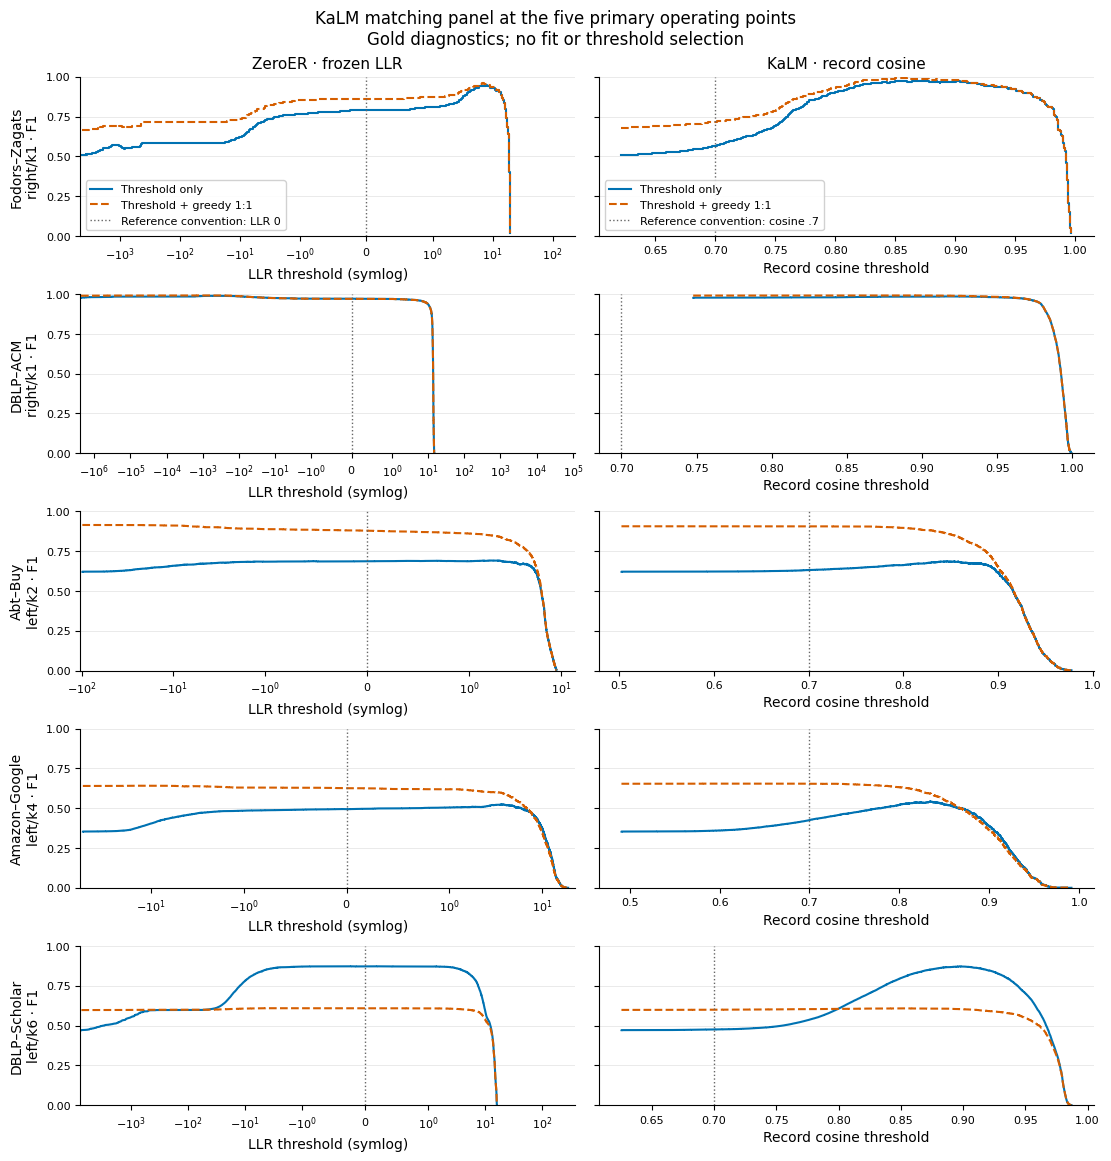

Saved /home/mda4172/Projects/pyJedAI/ZeroER/outputs/unsupervised_primary_thresholds.png


In [11]:
import matplotlib.pyplot as plt

ILLUSTRATION_MODEL = "tencent_KaLM-Embedding-Gemma3-12B-2511"
PRIMARY_THRESHOLD_FIGURE = Path(OUTPUT_DIR) / "unsupervised_primary_thresholds.png"


def read_primary_threshold_curves(database, experiment, primary_cells, model):
    """Read one SQLite snapshot of existing selected-fit curves; never refit."""
    curves, availability = {}, []
    score_names = ("llr", "record_cos:" + model)
    required = {(score, decoder) for score in score_names for decoder in ("threshold", "greedy")}
    if not Path(database).exists():
        return curves, pd.DataFrame([dict(dataset=d, side=s, k=k, available=False,
            status="unavailable: database missing") for d, s, k in primary_cells])
    with sqlite3.connect(Path(database).resolve().as_uri() + "?mode=ro", uri=True, timeout=120) as con:
        con.execute("BEGIN")
        tables = {row[0] for row in con.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        if not {"studies", "study_user_attributes", "trials", "unsupervised_thresholds"} <= tables:
            return curves, pd.DataFrame([dict(dataset=d, side=s, k=k, available=False,
                status="unavailable: stored threshold curves missing") for d, s, k in primary_cells])
        fits = pd.read_sql_query("""
            WITH attrs AS (
                SELECT study_id, json_group_object(key, json(value_json)) AS a
                FROM study_user_attributes GROUP BY study_id
            ), completed AS (
                SELECT study_id, number, row_number() OVER
                    (PARTITION BY study_id ORDER BY number DESC) AS retry_order
                FROM trials WHERE state='COMPLETE'
            )
            SELECT s.study_name, t.number AS trial_number,
                   json_extract(a, '$.dataset') AS dataset,
                   json_extract(a, '$.side') AS side,
                   json_extract(a, '$.k') AS k
            FROM studies s JOIN attrs USING (study_id) JOIN completed t USING (study_id)
            WHERE json_extract(a, '$.experiment')=?
              AND json_extract(a, '$.panel_name')=?
              AND json_extract(a, '$.phase')='full'
              AND json_extract(a, '$.role')='selected'
              AND coalesce(json_extract(a, '$.excluded'), 0)=0
              AND t.retry_order=1
        """, con, params=(experiment, "single:" + model))
        for dataset, side, k in primary_cells:
            rows = fits.loc[fits.dataset.eq(dataset) & fits.side.eq(side) & fits.k.eq(k)]
            info = dict(dataset=dataset, side=side, k=k, available=False)
            if len(rows) != 1:
                info["status"] = ("unavailable: selected refit pending or failed" if rows.empty
                                  else "unavailable: ambiguous selected studies")
                availability.append(info)
                continue
            fit = rows.iloc[0]
            stored = con.execute("""SELECT score_name, decoder, encoding, curve
                FROM unsupervised_thresholds WHERE study_name=? AND trial_number=?""",
                (fit.study_name, int(fit.trial_number))).fetchall()
            loaded, invalid = {}, []
            for score, decoder, encoding, payload in stored:
                if (score, decoder) not in required:
                    continue
                if encoding != "json+zlib":
                    invalid.append(score + "/" + decoder)
                    continue
                try:
                    curve = pd.DataFrame(json.loads(zlib.decompress(payload)))
                    cut = pd.to_numeric(curve["threshold"], errors="coerce")
                    curve = curve.assign(threshold=cut).loc[np.isfinite(cut)]
                    curve = curve.sort_values("threshold")
                    if curve.empty or not np.isfinite(curve["f1"]).all():
                        raise ValueError("no finite curve")
                except (KeyError, ValueError, TypeError, zlib.error):
                    invalid.append(score + "/" + decoder)
                    continue
                loaded[score, decoder] = curve
            missing = required - set(loaded)
            if missing or invalid:
                info["status"] = "unavailable: missing or invalid curve(s)"
            else:
                info.update(available=True, status="available", study_name=fit.study_name,
                            trial_number=int(fit.trial_number))
                curves[dataset, side, k] = loaded
            availability.append(info)
    return curves, pd.DataFrame(availability)


def plot_primary_threshold_curves(curves, primary_cells, model):
    """Make a standalone figure; absent points remain visibly unavailable."""
    labels = {"fodors_zagats": "Fodors–Zagats", "dblp_acm": "DBLP–ACM",
              "abt_buy": "Abt–Buy", "amazon_googleproducts": "Amazon–Google",
              "dblp_scholar": "DBLP–Scholar"}
    fig, axes = plt.subplots(len(primary_cells), 2, figsize=(11, 11.5), squeeze=False,
                             sharey=True, constrained_layout=True)
    for row, (dataset, side, k) in enumerate(primary_cells):
        data = curves.get((dataset, side, k), {})
        for col, (score, reference, axis_label) in enumerate(
                (("llr", 0., "LLR threshold (symlog)"),
                 ("record_cos:" + model, .7, "Record cosine threshold"))):
            ax = axes[row, col]
            for decoder, color, style, label in (
                    ("threshold", "#0072B2", "-", "Threshold only"),
                    ("greedy", "#D55E00", "--", "Threshold + greedy 1:1")):
                curve = data.get((score, decoder))
                if curve is not None:
                    # Inclusive cuts: a decision set at t persists until the
                    # previous distinct score when moving down the threshold.
                    ax.step(curve.threshold, curve.f1, where="pre", color=color,
                            linestyle=style, linewidth=1.5, label=label)
            ax.axvline(reference, color="0.4", linestyle=":", linewidth=1,
                       label="Reference convention: " + ("LLR 0" if col == 0 else "cosine .7"))
            if col == 0:
                ax.set_xscale("symlog", linthresh=1)
                ax.set_ylabel(labels.get(dataset, dataset) + "\n" + side + "/k" + str(k) + " · F1")
            if not data:
                ax.text(.5, .5, "Unavailable: selected fit or curve pending",
                        ha="center", va="center", transform=ax.transAxes, fontsize=9)
            ax.set_ylim(0, 1)
            ax.set_yticks([0, .25, .5, .75, 1])
            ax.set_xlabel(axis_label)
            ax.tick_params(labelsize=8)
            ax.grid(axis="y", color="0.9", linewidth=.6)
            ax.spines[["top", "right"]].set_visible(False)
            if row == 0:
                ax.set_title("ZeroER · frozen LLR" if col == 0 else "KaLM · record cosine", fontsize=11)
                ax.legend(loc="lower left", fontsize=8, framealpha=.9)
    fig.suptitle("KaLM matching panel at the five primary operating points\n"
                 "Gold diagnostics; no fit or threshold selection", fontsize=12)
    return fig


primary_threshold_curves, primary_threshold_availability = read_primary_threshold_curves(
    DATABASE, EXPERIMENT, PRIMARY_CELLS, ILLUSTRATION_MODEL)
PLOT_PRIMARY_THRESHOLDS = (len(primary_threshold_availability) == len(PRIMARY_CELLS)
                          and primary_threshold_availability.available.all())
if PLOT_PRIMARY_THRESHOLDS:
    primary_threshold_figure = plot_primary_threshold_curves(
        primary_threshold_curves, PRIMARY_CELLS, ILLUSTRATION_MODEL)
    PRIMARY_THRESHOLD_FIGURE.parent.mkdir(parents=True, exist_ok=True)
    primary_threshold_figure.savefig(PRIMARY_THRESHOLD_FIGURE, dpi=180, facecolor="white")
    display(primary_threshold_figure)
    plt.close(primary_threshold_figure)
    print("Saved", PRIMARY_THRESHOLD_FIGURE)
else:
    print("Threshold figure unavailable until all five selected fits and their curves are stored.")
    display(primary_threshold_availability)


## Interpretation of the primary results

- All five primary cells are covered. Across all declared fixed cuts, the highest observed mean F1 is **.81936** (F2LLM-v2-4B, LLR ≥ −5 plus greedy); **.81404** is its posterior ≥ .5 plus greedy result in the anchor comparison, not the full-grid maximum. Original B-paper/B-code at their original .5 cut score .6428/.5246. These are **gold-scored development comparisons**, not unsupervised choices of panel or threshold.
- With the same no-cut greedy decoder, gains are modest and inconsistent: F2LLM-v2-8B raw record cosine → LLR is .7622 → .7671; KaLM is .7662 → .7610. Across 135 panel/cell comparisons, LLR wins 58, ties 7 and loses 70.
- DBLP–Scholar's one-to-one oracle is only **.6178 F1**; threshold-only embedding results reach about .88. This gap reflects the gold standard's cardinality, so greedy is not a universally suitable decoder.
- Validation NLL selects fit settings **within a fixed representation**. It cannot choose between representations or determine the F1-optimal threshold. Convergence also does not establish match semantics: 131/135 primary fits converged, while the all-20 separate-column panel performs poorly.
- Prefer **LLR for ranking**. Posterior saturation creates score ties; LLR and posterior produce different no-cut greedy counts in 28/135 primary fits. Fixed cuts remain declared rules; gold-best cuts remain oracle diagnostics.
- For **LLR ≥ −5 plus greedy**, median matching time is **.1663 s for E5-large-v2** and **.1840 s for F2LLM-v2-4B** across the five primary cells (median of three repeats per cell, then median across cells). This includes fresh similarities, preprocessing, fitting, scoring and decoding; loading, embedding generation and blocking are excluded. Loading-inclusive totals and component timings are stored in the database. Direct record cosine is cheaper; see the [timing comparison](outputs/unsupervised_primary_timing_comparison.csv).
